# Practice 2 — Phân loại CIFAR-10 bằng Pretrained CNN
## So sánh VGG16 và DenseNet121

Bài thực hành khảo sát hiệu quả của **transfer learning**, **fine-tuning** và **learning rate** trên bài toán phân loại ảnh CIFAR-10.
Hai kiến trúc VGG16 và DenseNet121 được sử dụng với trọng số pretrained ImageNet-1K, thay classifier để dự đoán 10 lớp.

Ba cấu hình được áp dụng thống nhất cho mỗi kiến trúc, tạo thành sáu thí nghiệm.
Các thí nghiệm dùng cùng cách chia dữ liệu, tiền xử lý, seed, optimizer, batch size và ngân sách epoch.

Báo cáo gồm dữ liệu và EDA, tiền xử lý, kiến trúc, thiết kế thí nghiệm, huấn luyện, kết quả và phân tích lỗi.


In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

workspace = Path.cwd().resolve()
project = workspace if (workspace / 'src' / 'config.py').exists() else workspace / 'practice_2_pretrained_model'
if not (project / 'src' / 'config.py').exists():
    raise FileNotFoundError('Mở notebook từ workspace hoặc thư mục practice_2_pretrained_model.')
sys.path.insert(0, str(project / 'src'))
import config

def read_json(path):
    return json.loads(path.read_text(encoding='utf-8')) if path.exists() else None

eda = read_json(project / 'outputs' / 'eda.json')
print('Project:', project)
print('Cấu hình đang chọn:', config.MODEL_NAME, config.EXPERIMENT)


Project: D:\newtask\DL\practice_2_pretrained_model
Cấu hình đang chọn: vgg16 A


## 1. Dữ liệu và phân tích khám phá

CIFAR-10 gồm 60.000 ảnh RGB kích thước 32×32 thuộc 10 lớp.
Tập train chính thức gồm 50.000 ảnh được chia phân tầng thành **45.000 ảnh train** và **5.000 ảnh validation**, với seed 42.
**10.000 ảnh test** được giữ riêng để đánh giá sau khi chọn cấu hình bằng validation.

EDA kiểm tra số lượng ảnh, phân bố lớp, kích thước, kiểu dữ liệu, thống kê RGB và ảnh trùng chính xác.
Thống kê RGB được tính trên tập train; validation và test không được dùng để ước lượng tham số tiền xử lý.


Nguồn: CIFAR-10 official Python batches | Thời điểm: 2026-10-30T14:46:50.744838+00:00
Lớp: airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck
train 45000 ảnh | shape: [32, 32, 3] | dtype: uint8
validation 5000 ảnh | shape: [32, 32, 3] | dtype: uint8
test 10000 ảnh | shape: [32, 32, 3] | dtype: uint8


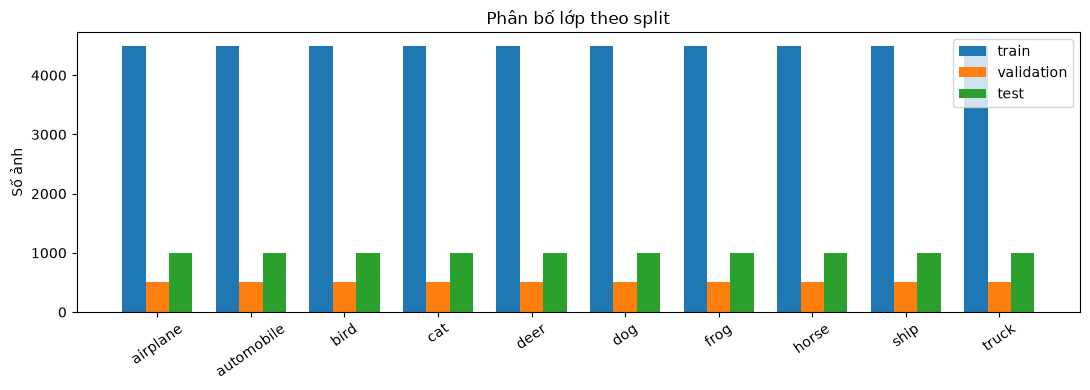

RGB train mean: [0.4911373512391069, 0.4821111870234205, 0.4464489876089326]
RGB train std: [0.24686913619557832, 0.2434301261262732, 0.26160339391516785]
Nhóm ảnh trùng chính xác: 0


,Mean,Std,P1,Median,P99
Đặc trưng train,,,,,
brightness,0.4732,0.1251,0.1966,0.4661,0.8019
contrast,0.1948,0.0604,0.0693,0.1932,0.3373
saturation,0.2737,0.1416,0.0000,0.2549,0.6724
edge,0.0559,0.0170,0.0192,0.0555,0.0976


Ảnh cực trị, phân bố theo split/lớp và bản đồ PCA toàn dataset xem trong visualization/eda.html. Biến thiên pixel không phải bằng chứng đủ để kết luận ảnh mờ hoặc sai nhãn.


In [2]:
if eda is None:
    print('Chưa có EDA report. Chuẩn bị dataset rồi chạy src/1_eda.py ngoài notebook.')
else:
    print('Nguồn:', eda['source'], '| Thời điểm:', eda['created'])
    print('Lớp:', ', '.join(eda['classes']))
    fig, ax = plt.subplots(figsize=(11, 4))
    x = np.arange(len(eda['classes']))
    for offset, (name, split) in enumerate(eda['splits'].items()):
        ax.bar(x + offset * 0.25, split['counts'], width=0.25, label=name)
        print(name, split['count'], 'ảnh | shape:', split['shape'], '| dtype:', split['dtype'])
    ax.set_xticks(x + 0.25, eda['classes'], rotation=35)
    ax.set_ylabel('Số ảnh'); ax.set_title('Phân bố lớp theo split'); ax.legend()
    plt.tight_layout(); plt.show()
    print('RGB train mean:', eda['train_rgb']['mean'])
    print('RGB train std:', eda['train_rgb']['std'])
    print('Nhóm ảnh trùng chính xác:', len(eda['duplicates']))

if eda and eda.get('deep_eda'):
    import pandas as pd
    from IPython.display import display
    deep = eda['deep_eda']
    rows = []
    for name in deep['feature_names']:
        values = deep['features'][name]['splits']['train']
        rows.append({'Đặc trưng train': name, 'Mean': values['mean'], 'Std': values['std'],
                     'P1': values['quantiles'][1], 'Median': values['quantiles'][3], 'P99': values['quantiles'][5]})
    display(pd.DataFrame(rows).set_index('Đặc trưng train').round(4))
    print('Ảnh cực trị, phân bố theo split/lớp và bản đồ PCA toàn dataset xem trong visualization/eda.html. '
          'Biến thiên pixel không phải bằng chứng đủ để kết luận ảnh mờ hoặc sai nhãn.')


### 1.1. Ảnh mẫu từng lớp

Mỗi lớp được minh họa bằng một ảnh gốc thuộc tập train, kèm tên lớp và chỉ số ảnh.
Các ảnh cho thấy sự đa dạng về hình dạng, màu sắc và bối cảnh; độ phân giải thấp có thể làm các lớp có đặc điểm gần nhau khó phân biệt.


In [3]:
from data import load_datasets, load_split

data_present = (project / 'data' / 'cifar-10-batches-py' / 'data_batch_1').exists()
if data_present:
    original, test_data = load_datasets(download=False)
    train_ids, val_ids = load_split(original.targets)
    examples = {}
    for index in train_ids:
        label = original.targets[index]
        if label not in examples:
            examples[label] = index
        if len(examples) == 10:
            break
    fig, axes = plt.subplots(2, 5, figsize=(11, 5))
    for label, ax in enumerate(axes.flat):
        index = examples[label]
        ax.imshow(original.data[index]); ax.set_title(f'{original.classes[label]} — ID {index}')
        ax.axis('off')
    plt.tight_layout(); plt.show()
    del original, test_data
else:
    print('Không có dataset local; bỏ qua ảnh mẫu, không tải tự động.')


## 2. Tiền xử lý dữ liệu

Các ảnh được resize thành **224×224**, chuyển sang tensor trong khoảng [0,1] và chuẩn hóa theo từng kênh màu bằng thống kê ImageNet:

$$x'_{c} = \frac{x_c-\mu_c}{\sigma_c}$$

Trong đó $\mu=(0.485,0.456,0.406)$ và $\sigma=(0.229,0.224,0.225)$ theo thứ tự R, G, B.
Tập train được bổ sung random horizontal flip; validation và test không sử dụng biến đổi ngẫu nhiên.

Chuẩn hóa ImageNet duy trì thang đầu vào phù hợp với pretrained weights. Resize không khôi phục chi tiết đã mất từ ảnh gốc 32×32.
Hình minh họa thể hiện ảnh gốc, ảnh resize, ảnh lật và ảnh sau khi đảo normalization.


In [4]:
print('Image size:', config.IMAGE_SIZE)
print('ImageNet mean:', config.IMAGENET_MEAN)
print('ImageNet std:', config.IMAGENET_STD)
if eda:
    import base64
    from io import BytesIO
    from PIL import Image
    fig, axes = plt.subplots(1, 4, figsize=(11, 3))
    for ax, name in zip(axes, ('original', 'resized', 'flipped', 'restored')):
        payload = eda['preprocessing'][name].split(',', 1)[1]
        ax.imshow(Image.open(BytesIO(base64.b64decode(payload))))
        ax.set_title(name); ax.axis('off')
    plt.tight_layout(); plt.show()


Image size: 224
ImageNet mean: (0.485, 0.456, 0.406)
ImageNet std: (0.229, 0.224, 0.225)


## 3. Kiến trúc và điều chỉnh mô hình

**VGG16** sử dụng các block convolution 3×3 xếp tuần tự.
**DenseNet121** nối đặc trưng từ các lớp trước trong cùng dense block để tái sử dụng thông tin.
Cả hai sử dụng pretrained weights **ImageNet-1K, IMAGENET1K_V1**, thay head 1.000 lớp bằng classifier 10 lớp.

| Model | Backbone và head | Nhóm mở khi fine-tune |
|---|---|---|
| VGG16 | features → GAP 1×1 → flatten → Linear(512,10) | Ba convolution cuối: features.24/26/28 |
| DenseNet121 | features → ReLU → GAP 1×1 → flatten → Linear(1024,10) | denseblock4 và norm5 |

- **Transfer learning:** freeze backbone, chỉ cập nhật head mới.
- **Fine-tuning:** cập nhật thêm nhóm cuối; các nhóm trước vẫn freeze.
- Running statistics của BatchNorm được giữ cố định. Affine parameters chỉ được học nếu thuộc nhóm mở.

Cell thống kê kiến trúc dùng weights ngẫu nhiên trên CPU; số tham số không phụ thuộc giá trị weights. Đây không phải kết quả đánh giá model đã train.


In [5]:
from model import PretrainedCNN

example_model = PretrainedCNN(config.MODEL_NAME, fine_tune=config.FINE_TUNE, pretrained=False)
print('Model:', example_model.name)
print('Head:', example_model.head)
print('Nhóm cuối:', example_model.final_blocks)
print('Fine-tune:', example_model.fine_tune)
print('Tổng tham số:', sum(p.numel() for p in example_model.parameters()))
print('Tham số được học:', sum(p.numel() for p in example_model.parameters() if p.requires_grad))
del example_model


Model: vgg16
Head: Linear(in_features=512, out_features=10, bias=True)
Nhóm cuối: ('24', '26', '28')
Fine-tune: False
Tổng tham số: 14719818
Tham số được học: 5130


## 4. Thiết kế thí nghiệm

Mỗi kiến trúc được huấn luyện với ba cấu hình sau:

| Cấu hình | Backbone | Head | Learning rate | Batch size |
|---|---|---|---:|---:|
| A | Freeze | Linear → 10 | 0.001 | 64 |
| B | Mở nhóm cuối | Linear → 10 | 0.001 | 64 |
| C | Mở nhóm cuối | Linear → 10 | 0.0001 | 64 |

**A so với B** khảo sát tác động của fine-tuning. **B so với C** khảo sát tác động của learning rate.
VGG16 và DenseNet121 được so sánh trong cùng cấu hình.

Điều kiện chung: split seed 42, Adam, CrossEntropyLoss, weight decay 0 và 20 epoch mỗi lượt; không sử dụng scheduler hoặc early stopping.
Mỗi thí nghiệm mới bắt đầu từ pretrained weights, không kế thừa weights đã học từ cấu hình khác.


In [6]:
for name in config.MODEL_NAMES:
    for experiment, values in config.EXPERIMENTS.items():
        print(name, experiment, values)
print('Epoch/lượt:', config.EPOCHS, '| seed:', config.SEED, '| workers:', config.NUM_WORKERS)


vgg16 A {'head': 'H1', 'fine_tune': False, 'lr': 0.001, 'batch_size': 64}
vgg16 B {'head': 'H1', 'fine_tune': True, 'lr': 0.001, 'batch_size': 64}
vgg16 C {'head': 'H1', 'fine_tune': True, 'lr': 0.0001, 'batch_size': 64}
densenet121 A {'head': 'H1', 'fine_tune': False, 'lr': 0.001, 'batch_size': 64}
densenet121 B {'head': 'H1', 'fine_tune': True, 'lr': 0.001, 'batch_size': 64}
densenet121 C {'head': 'H1', 'fine_tune': True, 'lr': 0.0001, 'batch_size': 64}
Epoch/lượt: 20 | seed: 42 | workers: 0


## 5. Quy trình huấn luyện và lưu mô hình

Mỗi epoch gồm hai giai đoạn:

1. **Training:** đặt model ở chế độ train; xóa gradient; forward; tính CrossEntropyLoss; backward; cập nhật tham số bằng Adam.
2. **Validation:** chuyển sang eval và no_grad; tính loss, accuracy mà không cập nhật trọng số.

Loss được lấy trung bình theo số ảnh, accuracy là tỷ lệ dự đoán đúng.
Train/validation loss, accuracy, learning rate và thời gian được ghi sau mỗi epoch, đồng thời theo dõi bằng TensorBoard.

- **best.pt:** checkpoint có validation accuracy cao nhất; nếu hòa, ưu tiên validation loss thấp hơn rồi epoch sớm hơn.
- **last.pt:** trạng thái cuối epoch hoàn tất, gồm weights, optimizer và random state để tiếp tục khi gián đoạn.

Việc huấn luyện được thực hiện bằng script Python; các biểu đồ sau được tổng hợp từ kết quả đã lưu.


## 6. Kết quả huấn luyện

Kết quả được đọc từ cấu hình thực tế, history và checkpoint của từng lượt chạy.
Mỗi lượt được nhận diện bằng model, cấu hình, số epoch đã hoàn tất và thiết bị sử dụng.

Các đường cong thể hiện train/validation loss và accuracy theo epoch.
Lượt chưa hoàn thành được ghi rõ số epoch hiện có và không được xem là kết quả cuối của ngân sách 20 epoch.

Train và validation được vẽ riêng theo epoch. Test là cột tại best checkpoint, không phải đường test theo epoch.


In [7]:
import torch

runs = []
for folder in sorted((project / 'outputs' / 'runs').glob('lan_*')):
    metadata = read_json(folder / 'config.json')
    history = read_json(folder / 'history.json') or []
    if not metadata:
        continue
    settings = metadata['settings']
    epochs = {}
    for filename in ('best.pt', 'last.pt'):
        path = folder / filename
        if path.exists():
            checkpoint = torch.load(path, map_location='cpu', weights_only=False)
            epochs[filename] = checkpoint['epoch']
            del checkpoint
    complete = len(history) == settings['train']['epochs']
    compatible = (settings['model_name'] in config.MODEL_NAMES and
                  settings['model_config'] in config.EXPERIMENTS.values())
    print(folder.name, settings['model_name'], settings['model_config'])
    print('Epoch hoàn tất:', len(history), '/', settings['train']['epochs'], '| checkpoint:', epochs)
    print('Đủ epoch:', complete, '| khớp thiết kế thí nghiệm:', compatible,
          '| device:', metadata['environment']['device'])
    print('Nguồn:', folder / 'history.json')
    if history:
        best = max(history, key=lambda row: (row['val_accuracy'], -row['val_loss'], -row['epoch']))
        print('Best validation:', f"{100 * best['val_accuracy']:.2f}%", '| epoch:', best['epoch'])
    runs.append((folder, settings, history))
if not runs:
    print('Chưa có lịch sử train và cấu hình run để hiển thị kết quả huấn luyện.')

import pandas as pd
from IPython.display import display

summary_rows = []
for folder, settings, history in runs:
    metadata = read_json(folder / 'config.json')
    train = read_json(folder / 'train_metrics.json')
    validation = read_json(folder / 'validation_metrics.json')
    test = read_json(folder / 'test_metrics.json')
    if not all((train, validation, test)):
        continue
    if len({row['checkpoint_sha256'] for row in (train, validation, test)}) != 1:
        raise ValueError('Các split không dùng cùng best checkpoint: ' + folder.name)
    parameters = metadata.get('parameters', {})
    environment = metadata.get('environment', {})
    gpu = environment.get('gpu', [])
    hardware = ', '.join(item.get('name', '') for item in gpu) or environment.get('device', 'unknown')
    summary_rows.append({
        'Run': folder.name, 'Model': settings['model_name'], 'Cấu hình': settings['experiment'],
        'Best epoch': test['epoch'], 'Epoch hoàn tất': len(history),
        'Train eval (%)': 100 * train['accuracy'], 'Val eval (%)': 100 * validation['accuracy'],
        'Test (%)': 100 * test['accuracy'], 'Val loss': validation['loss'], 'Test loss': test['loss'],
        'Test macro F1': test['macro_f1'], 'Gap train-val (điểm %)': 100 * (train['accuracy'] - validation['accuracy']),
        'Tổng tham số': parameters.get('total'), 'Tham số train': parameters.get('trainable'),
        'Tổng thời gian epoch (phút)': sum(row.get('seconds', 0) for row in history) / 60,
        'Máy train': hardware,
    })
if summary_rows:
    summary_table = pd.DataFrame(summary_rows).sort_values(['Model', 'Cấu hình'])
    display(summary_table.round(4).set_index('Run'))
    print('Train/val/test trong bảng được đánh giá ở cùng best checkpoint; '
          'train online trên đường cong có augmentation và khác phép đo này. '
          'Thời gian là tổng epoch được ghi, không gồm mọi chi phí; khác máy nên không dùng để xếp hạng tốc độ kiến trúc.')


lan_1 densenet121 {'head': 'H1', 'fine_tune': False, 'lr': 0.001, 'batch_size': 64}
Epoch hoàn tất: 20 / 20 | checkpoint: {'best.pt': 10, 'last.pt': 20}
Đủ epoch: True | khớp thiết kế thí nghiệm: True | device: cuda
Nguồn: D:\newtask\DL\practice_2_pretrained_model\outputs\runs\lan_1\history.json
Best validation: 90.52% | epoch: 10


lan_2 densenet121 {'head': 'H1', 'fine_tune': True, 'lr': 0.001, 'batch_size': 64}
Epoch hoàn tất: 20 / 20 | checkpoint: {'best.pt': 7, 'last.pt': 20}
Đủ epoch: True | khớp thiết kế thí nghiệm: True | device: mps
Nguồn: D:\newtask\DL\practice_2_pretrained_model\outputs\runs\lan_2\history.json
Best validation: 92.86% | epoch: 7


lan_3 densenet121 {'head': 'H1', 'fine_tune': True, 'lr': 0.0001, 'batch_size': 64}
Epoch hoàn tất: 20 / 20 | checkpoint: {'best.pt': 16, 'last.pt': 20}
Đủ epoch: True | khớp thiết kế thí nghiệm: True | device: cuda
Nguồn: D:\newtask\DL\practice_2_pretrained_model\outputs\runs\lan_3\history.json
Best validation: 93.90% | epoch: 16
lan_4 vgg16 {'head': 'H1', 'fine_tune': False, 'lr': 0.001, 'batch_size': 64}
Epoch hoàn tất: 20 / 20 | checkpoint: {'best.pt': 20, 'last.pt': 20}
Đủ epoch: True | khớp thiết kế thí nghiệm: True | device: cuda
Nguồn: D:\newtask\DL\practice_2_pretrained_model\outputs\runs\lan_4\history.json
Best validation: 85.62% | epoch: 20
lan_5 vgg16 {'head': 'H1', 'fine_tune': True, 'lr': 0.001, 'batch_size': 64}
Epoch hoàn tất: 20 / 20 | checkpoint: {'best.pt': 20, 'last.pt': 20}
Đủ epoch: True | khớp thiết kế thí nghiệm: True | device: cuda
Nguồn: D:\newtask\DL\practice_2_pretrained_model\outputs\runs\lan_5\history.json
Best validation: 91.96% | epoch: 20


lan_6 vgg16 {'head': 'H1', 'fine_tune': True, 'lr': 0.0001, 'batch_size': 64}
Epoch hoàn tất: 20 / 20 | checkpoint: {'best.pt': 19, 'last.pt': 20}
Đủ epoch: True | khớp thiết kế thí nghiệm: True | device: cuda
Nguồn: D:\newtask\DL\practice_2_pretrained_model\outputs\runs\lan_6\history.json
Best validation: 93.24% | epoch: 19


,Model,Cấu hình,Best epoch,Epoch hoàn tất,Train eval (%),Val eval (%),Test (%),Val loss,Test loss,Test macro F1,Gap train-val (điểm %),Tổng tham số,Tham số train,Tổng thời gian epoch (phút),Máy train
Run,,,,,,,,,,,,,,,
lan_1,densenet121,A,10,20,91.7867,90.50,90.01,0.2928,0.2965,0.9001,1.2867,6964106,10250,105.0428,Quadro T2000
lan_2,densenet121,B,7,20,97.7600,92.86,93.06,0.2482,0.2502,0.9302,4.9000,6964106,2170378,107.3619,mps
lan_3,densenet121,C,16,20,99.7511,93.88,93.48,0.3168,0.3283,0.9350,5.8711,6964106,2170378,135.8561,Quadro T2000
lan_4,vgg16,A,20,20,86.1667,85.62,84.48,0.4198,0.4478,0.8446,0.5467,14719818,5130,120.6253,Tesla T4
lan_5,vgg16,B,20,20,99.4378,91.96,91.91,0.4675,0.4602,0.9188,7.4778,14719818,7084554,119.4504,"Tesla T4, Tesla T4"
lan_6,vgg16,C,19,20,99.8822,93.24,93.10,0.3231,0.3242,0.9310,6.6422,14719818,7084554,130.5704,"Tesla T4, Tesla T4"


Train/val/test trong bảng được đánh giá ở cùng best checkpoint; train online trên đường cong có augmentation và khác phép đo này. Thời gian là tổng epoch được ghi, không gồm mọi chi phí; khác máy nên không dùng để xếp hạng tốc độ kiến trúc.


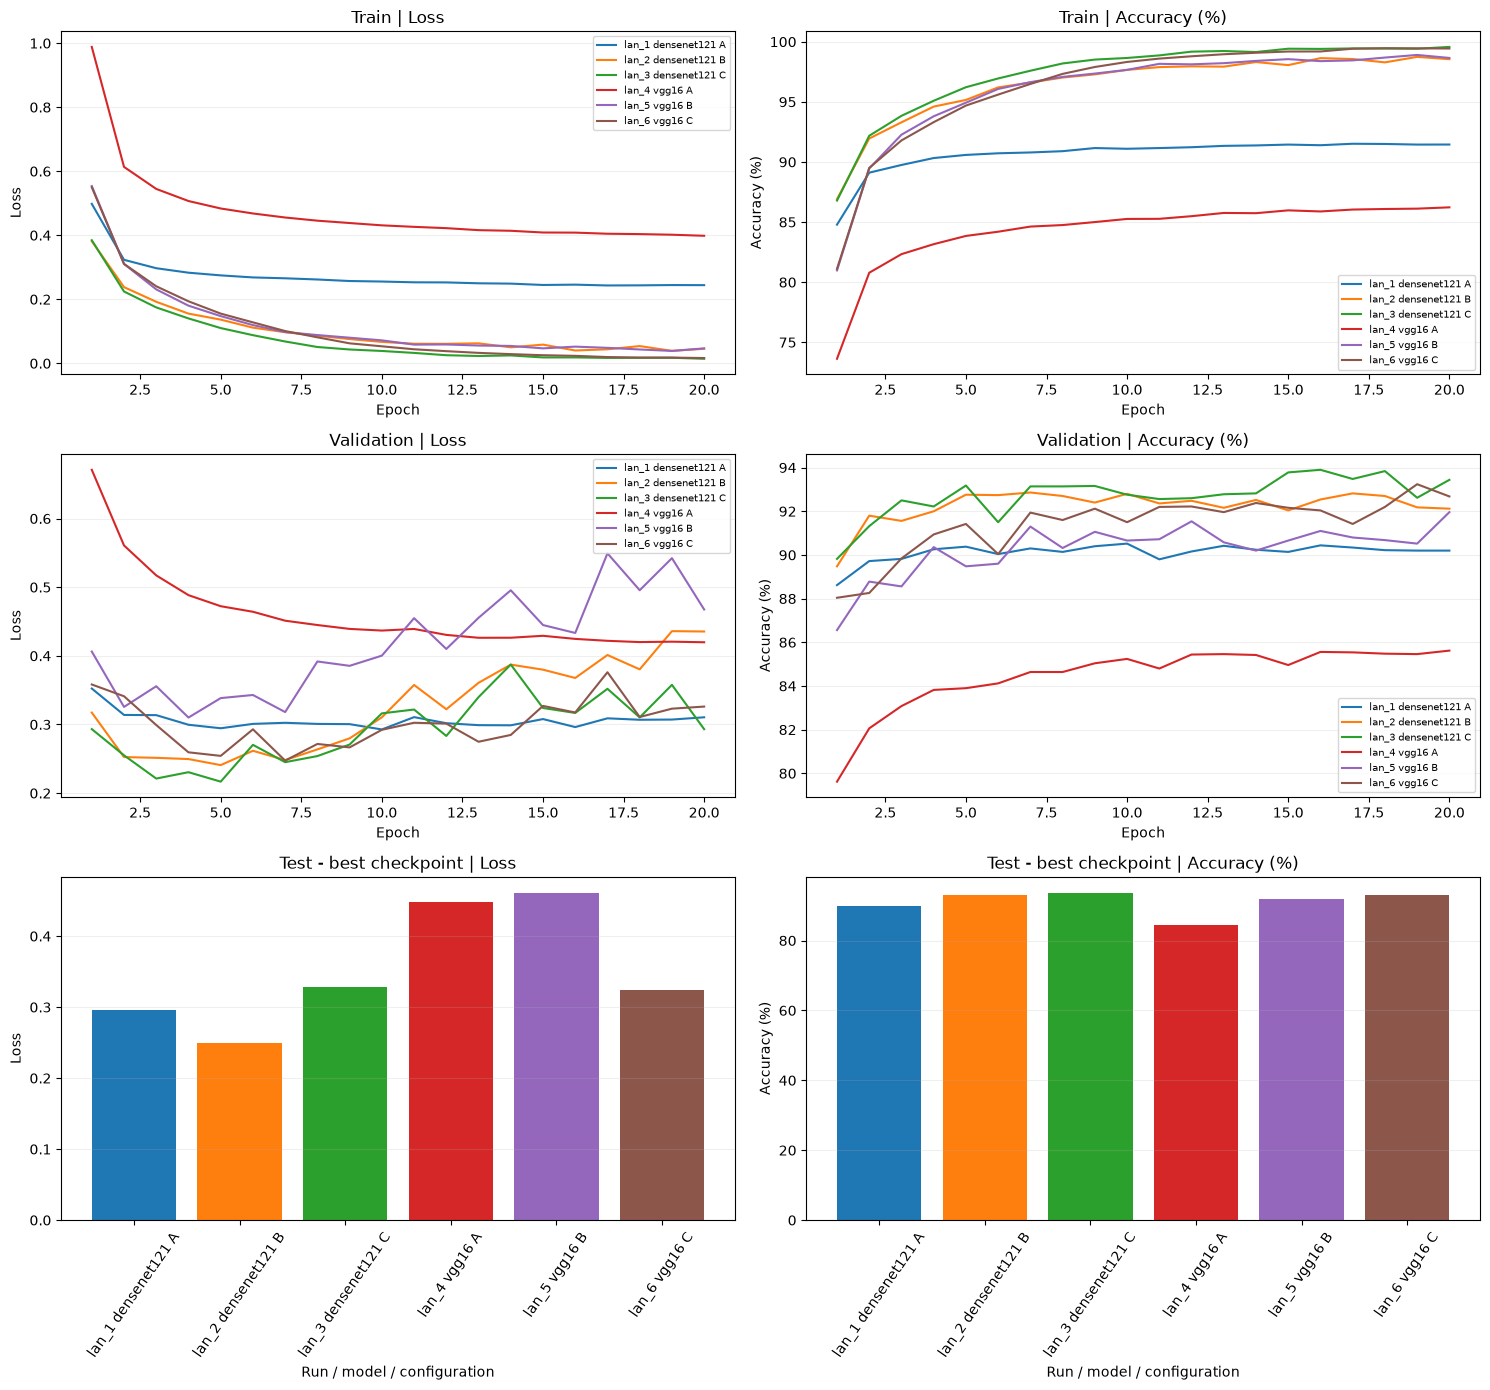

In [8]:
# Each row is one split; test is a checkpoint measurement, not an epoch curve.
if runs:
    fig, axes = plt.subplots(3, 2, figsize=(15, 14))
    colors = plt.get_cmap('tab10')
    for index, (folder, settings, history) in enumerate(runs):
        label = f"{folder.name} {settings['model_name']} {settings['experiment']}"
        color = colors(index % 10)
        if history:
            epochs = [row['epoch'] for row in history]
            for row_index, prefix in enumerate(('train', 'val')):
                axes[row_index, 0].plot(epochs, [row[prefix + '_loss'] for row in history],
                                        label=label, color=color)
                axes[row_index, 1].plot(epochs, [100 * row[prefix + '_accuracy'] for row in history],
                                        label=label, color=color)
        test_report = read_json(folder / 'test_metrics.json')
        if test_report:
            axes[2, 0].bar(label, test_report['loss'], color=color)
            axes[2, 1].bar(label, 100 * test_report['accuracy'], color=color)
    for row_index, split in enumerate(('Train', 'Validation', 'Test - best checkpoint')):
        for col_index, metric in enumerate(('Loss', 'Accuracy (%)')):
            ax = axes[row_index, col_index]
            ax.set_title(split + ' | ' + metric)
            ax.set_ylabel(metric)
            ax.grid(alpha=0.2, axis='y')
            if row_index < 2:
                ax.set_xlabel('Epoch')
                ax.legend(fontsize=7)
            else:
                ax.set_xlabel('Run / model / configuration')
                ax.tick_params(axis='x', labelrotation=55)
    plt.tight_layout(); plt.show()


## 7. Đánh giá và phân tích lỗi

Các chỉ số đánh giá gồm loss, accuracy, macro-F1 và precision/recall/F1 theo từng lớp.
Confusion matrix chuẩn hóa theo hàng thể hiện tỷ lệ dự đoán của từng lớp thật: trục dọc là nhãn thật, trục ngang là nhãn dự đoán.

Validation được dùng để chọn cấu hình và checkpoint. Test chỉ được đánh giá sau khi khóa lựa chọn của từng model.
Báo cáo kết quả phân biệt rõ tập dữ liệu, checkpoint epoch và model được sử dụng; phần dưới hiển thị các báo cáo đánh giá đã có.


### 7.0. Chạy đánh giá từ checkpoint

Checkpoint được đặt tại `outputs/runs/lan_N/best.pt`, sử dụng định dạng đầy đủ của dự án: `model_state`, `settings`, `classes`, `weights`, `epoch`.
Dataset CIFAR-10 và `outputs/cifar10_split.json` cần có trên máy; split phải khớp SHA-256 đã lưu khi train.
File chỉ chứa state_dict riêng lẻ chưa đủ thông tin để xác định cấu hình thí nghiệm.

Cell sau gọi lại `src/3_evaluate.py`, không huấn luyện lại model:

1. Điền `EVALUATION_RUNS` bằng tên các thư mục checkpoint, ví dụ `['lan_1', 'lan_2']`.
2. Đặt `RUN_EVALUATION=True` để thực thi. Mặc định False chỉ xem các kết quả đã lưu.
3. Đặt `EVALUATE_TEST=True` sau khi đã khóa checkpoint bằng validation; False chỉ đánh giá train/validation.
4. Chạy cell đánh giá, rồi chạy các cell phía dưới để in bảng và biểu đồ.

Mỗi lần thực thi cập nhật báo cáo tương ứng trong thư mục run, gồm xác suất 10 lớp khi đánh giá test.
Cấu hình notebook được áp dụng cho lần chạy này; file config.py và trọng số checkpoint không bị thay đổi.

Chế độ đọc báo cáo không có nghĩa model chưa đánh giá: RUN_EVALUATION=False dùng lại JSON, True nạp best.pt để chạy inference lại. Xem lại bảng/biểu đồ không cần chạy test lần nữa.


In [9]:
import runpy

EVALUATION_RUNS = ['lan_1']
RUN_EVALUATION = False
EVALUATE_TEST = False

if RUN_EVALUATION:
    for run_name in EVALUATION_RUNS:
        checkpoint_path = project / 'outputs' / 'runs' / run_name / 'best.pt'
        if not checkpoint_path.is_file():
            raise FileNotFoundError(f'Không có checkpoint: {checkpoint_path}')
    previous_run, previous_test = config.EVAL_RUN, config.RUN_TEST
    try:
        for run_name in EVALUATION_RUNS:
            config.EVAL_RUN = run_name
            config.RUN_TEST = EVALUATE_TEST
            print('Đánh giá:', run_name, '| gồm test:', EVALUATE_TEST)
            runpy.run_path(str(project / 'src' / '3_evaluate.py'), run_name='__main__')
    finally:
        config.EVAL_RUN, config.RUN_TEST = previous_run, previous_test
else:
    print('Đang hiển thị kết quả JSON đã đánh giá; không chạy inference lại. Các kết quả test hiện có vẫn được phân tích phía dưới.')


Đang hiển thị kết quả JSON đã đánh giá; không chạy inference lại. Các kết quả test hiện có vẫn được phân tích phía dưới.


lan_1 densenet121 train epoch 10 | accuracy: 0.9178666666666667 | loss: 0.23919418828222486 | macro-F1: 0.9179221273421057
lan_1 densenet121 validation epoch 10 | accuracy: 0.905 | loss: 0.29277246646881105 | macro-F1: 0.9049730180141866
lan_1 densenet121 test epoch 10 | accuracy: 0.9001 | loss: 0.2964694299697876 | macro-F1: 0.9001354897188836


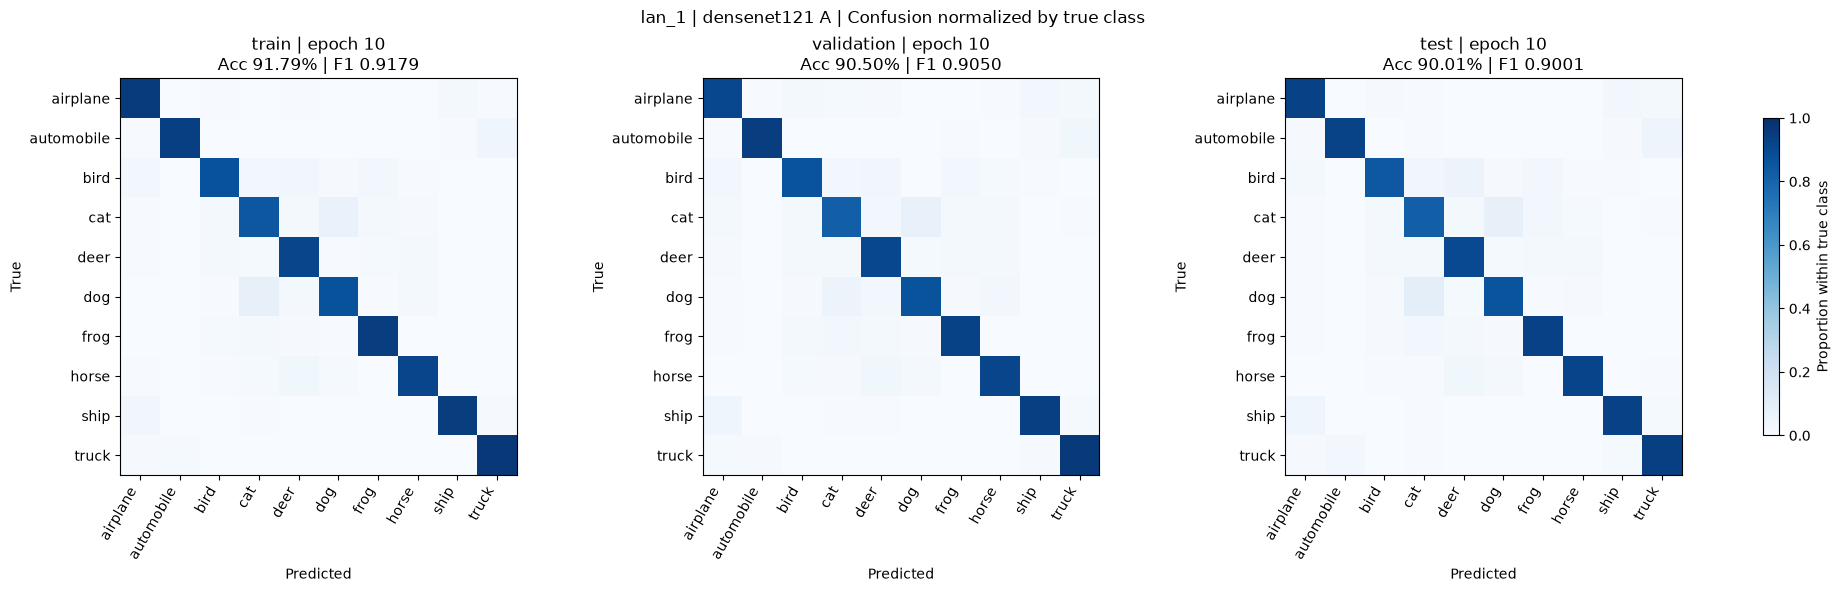

lan_2 densenet121 train epoch 7 | accuracy: 0.9776 | loss: 0.0643863910815782 | macro-F1: 0.9774780373724014
lan_2 densenet121 validation epoch 7 | accuracy: 0.9286 | loss: 0.2482197130203247 | macro-F1: 0.928072808924339
lan_2 densenet121 test epoch 7 | accuracy: 0.9306 | loss: 0.25015005452632905 | macro-F1: 0.9301622356137379


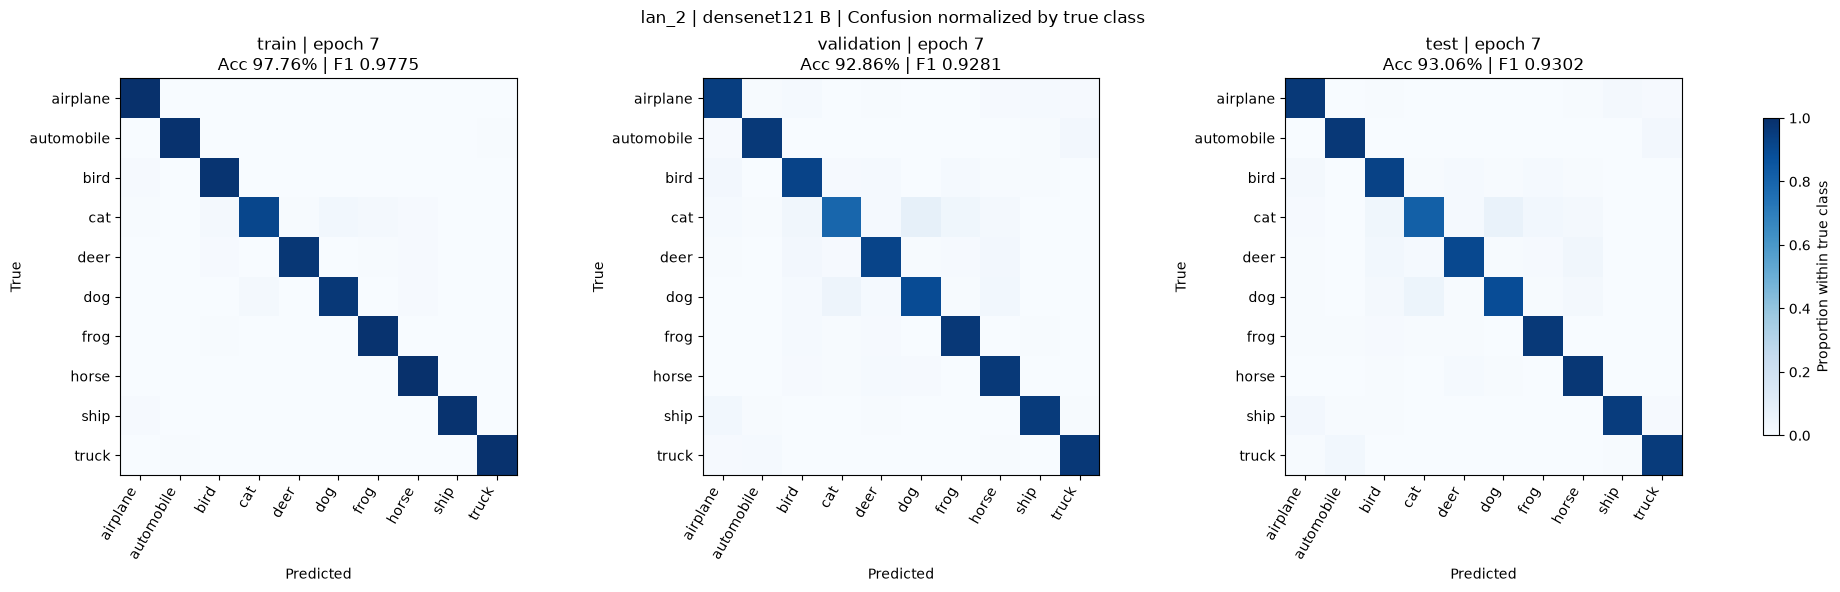

lan_3 densenet121 train epoch 16 | accuracy: 0.9975111111111111 | loss: 0.007782696501056004 | macro-F1: 0.9975119918664401
lan_3 densenet121 validation epoch 16 | accuracy: 0.9388 | loss: 0.31679879837036135 | macro-F1: 0.938992536947157
lan_3 densenet121 test epoch 16 | accuracy: 0.9348 | loss: 0.3283284949660301 | macro-F1: 0.9349720183469383


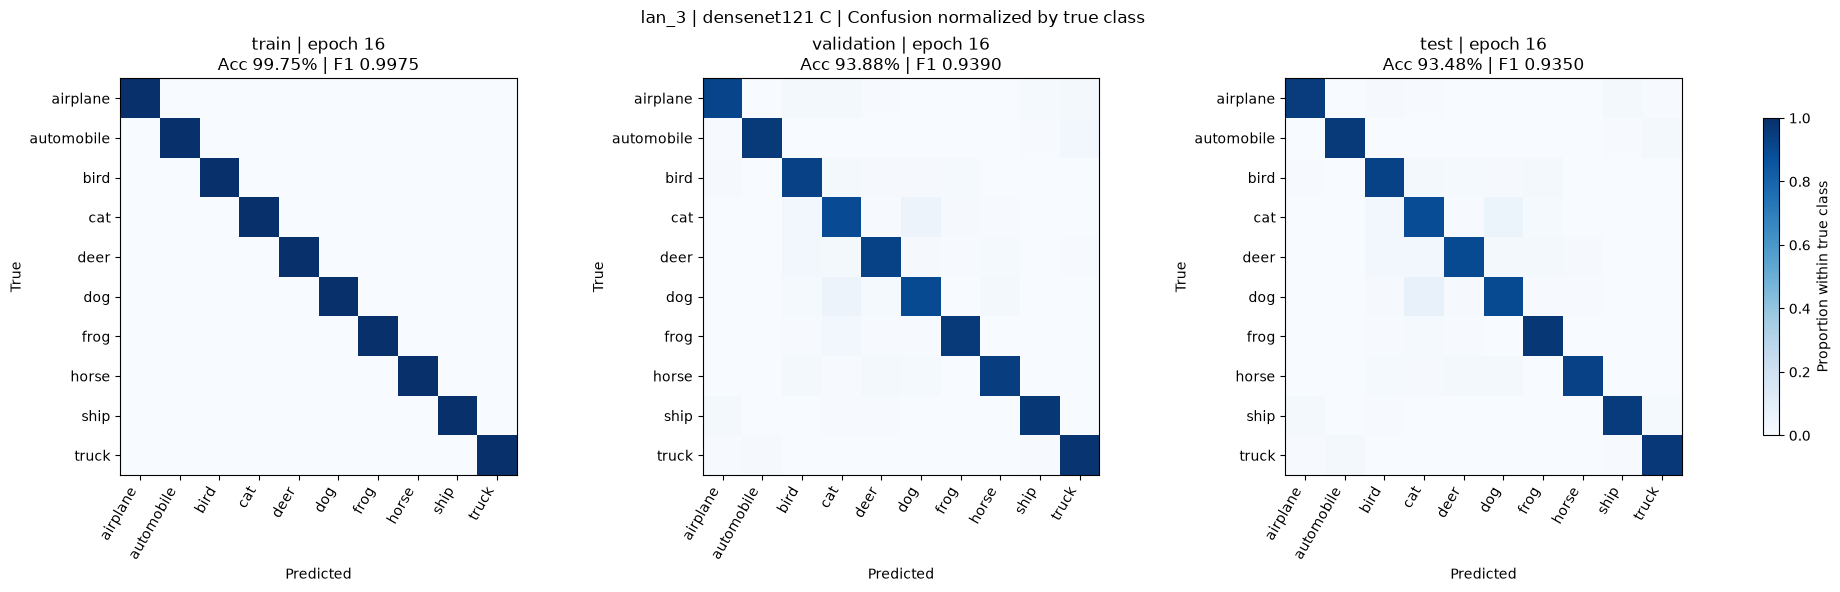

lan_4 vgg16 train epoch 20 | accuracy: 0.8616666666666667 | loss: 0.3973774208757612 | macro-F1: 0.8614948160322967
lan_4 vgg16 validation epoch 20 | accuracy: 0.8562 | loss: 0.4198032898902893 | macro-F1: 0.8563758524999262
lan_4 vgg16 test epoch 20 | accuracy: 0.8448 | loss: 0.4477578317642212 | macro-F1: 0.8445888146839611


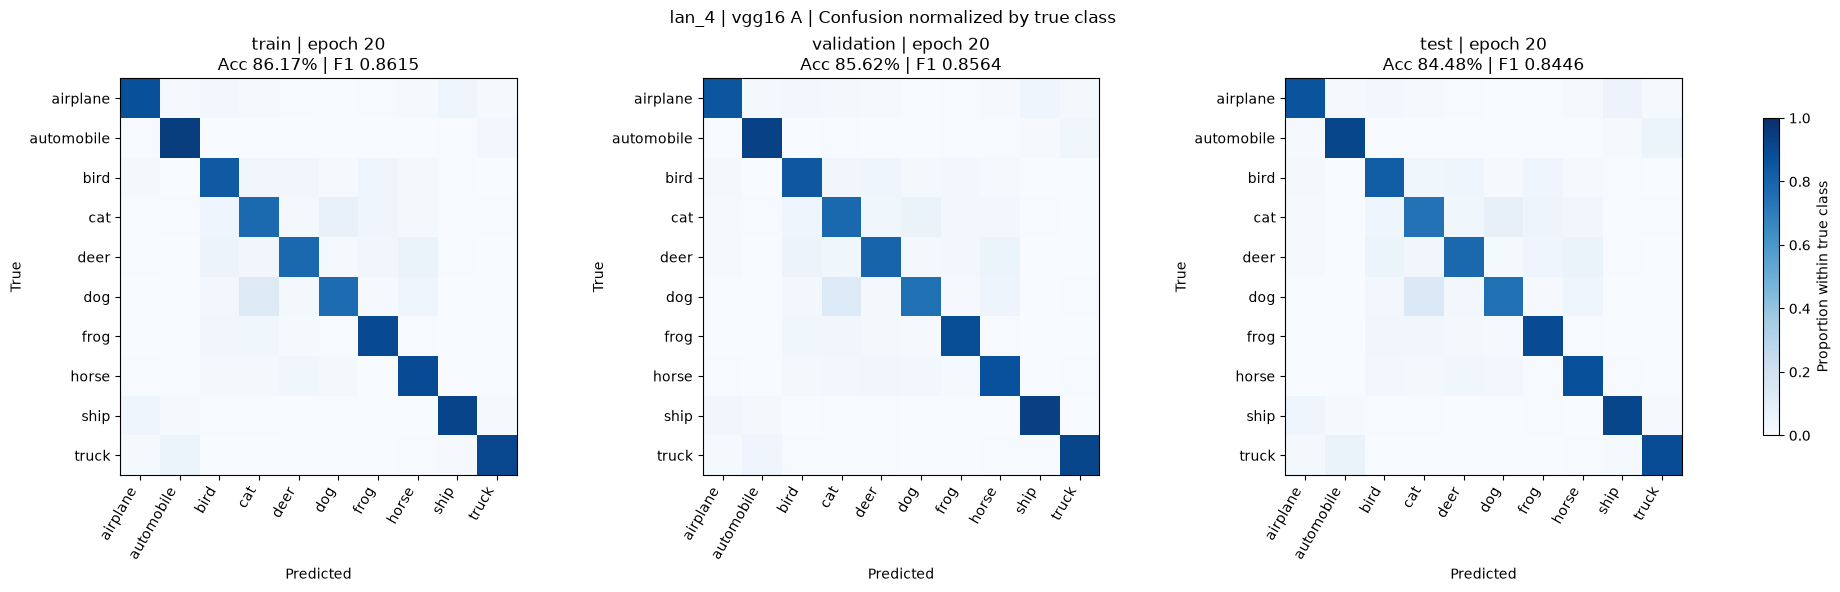

lan_5 vgg16 train epoch 20 | accuracy: 0.9943777777777778 | loss: 0.01688400454856326 | macro-F1: 0.9943763752507632
lan_5 vgg16 validation epoch 20 | accuracy: 0.9196 | loss: 0.46754335680007936 | macro-F1: 0.9193603881795802
lan_5 vgg16 test epoch 20 | accuracy: 0.9191 | loss: 0.4602100221574307 | macro-F1: 0.9188042278427998


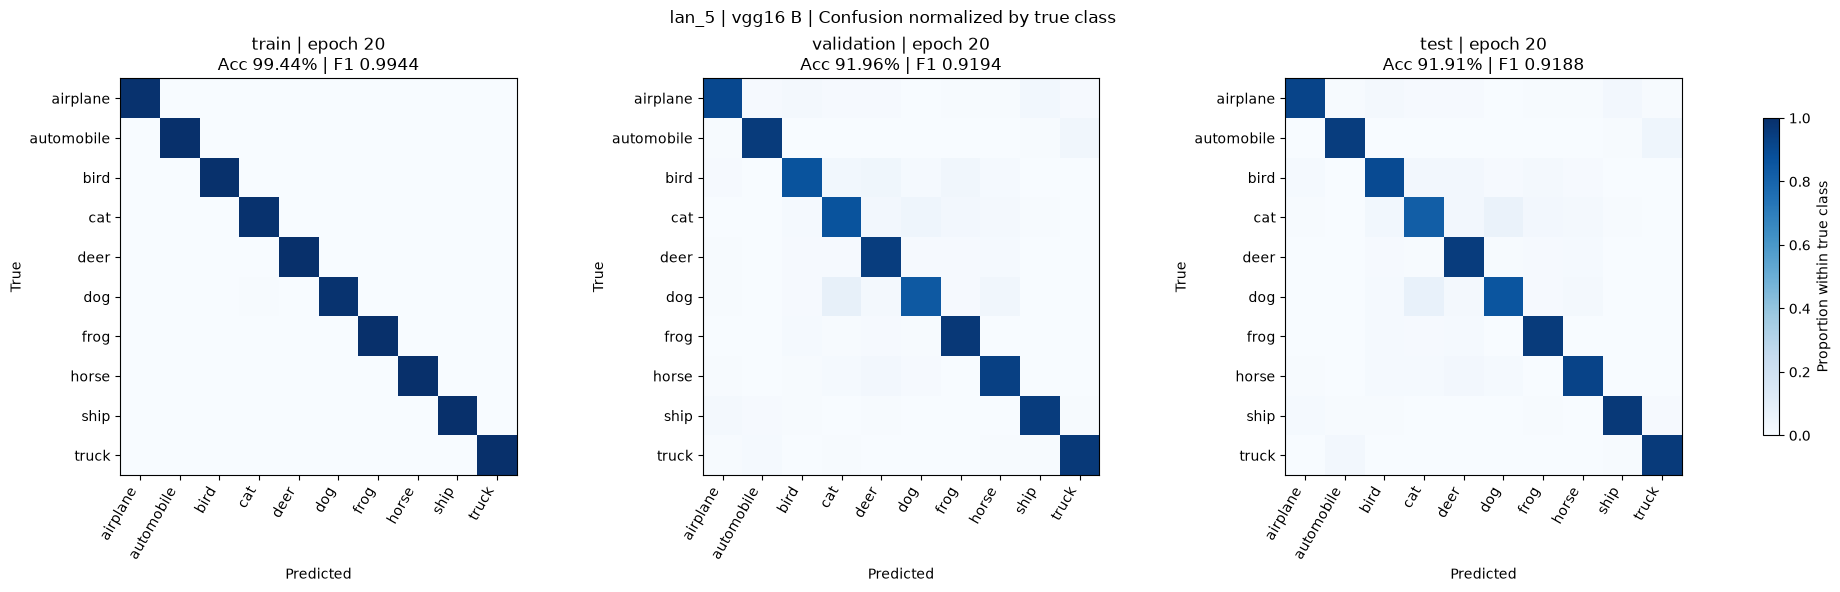

lan_6 vgg16 train epoch 19 | accuracy: 0.9988222222222222 | loss: 0.0050554239415408425 | macro-F1: 0.9988225293297462
lan_6 vgg16 validation epoch 19 | accuracy: 0.9324 | loss: 0.32305740604400635 | macro-F1: 0.932566818264173
lan_6 vgg16 test epoch 19 | accuracy: 0.931 | loss: 0.3241777034327388 | macro-F1: 0.9310195046933961


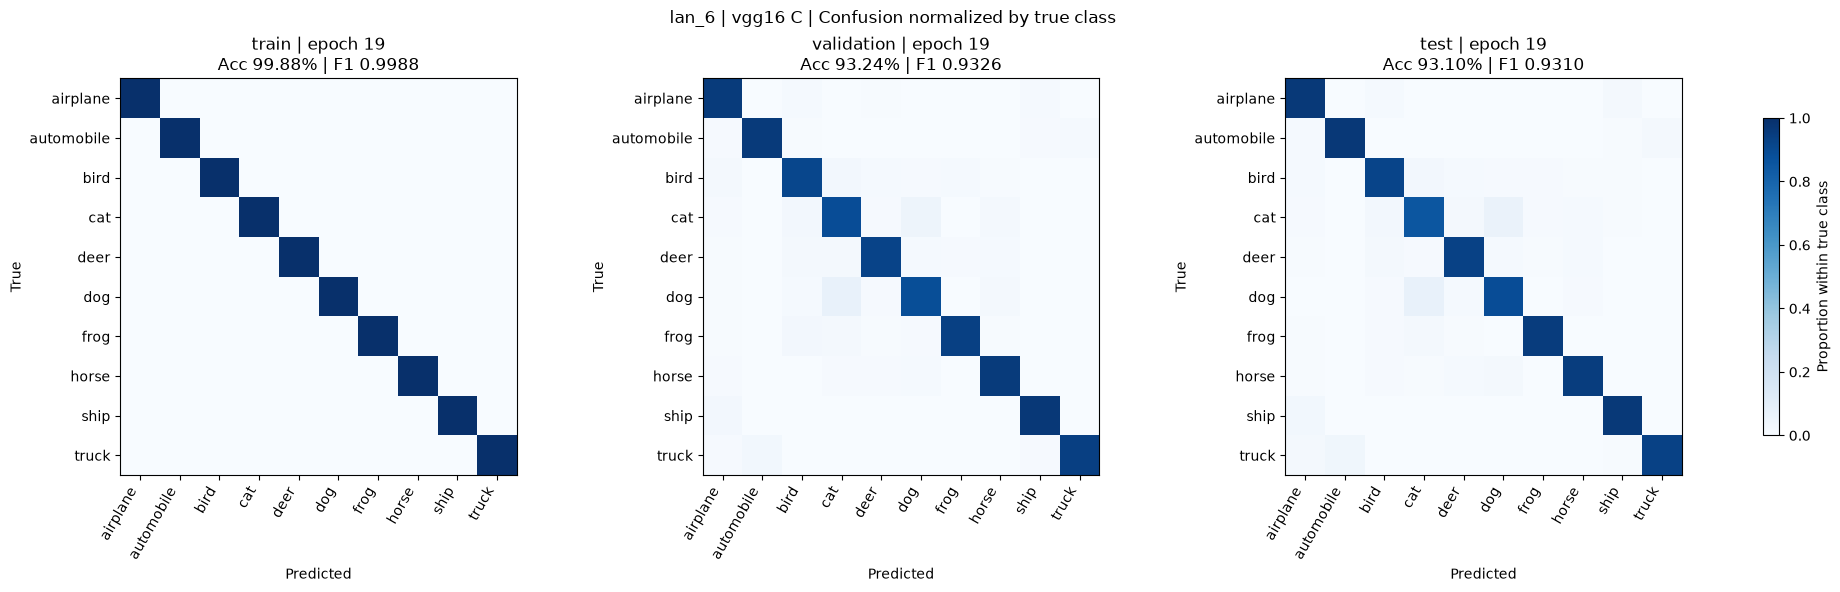

In [10]:
reports = []
for folder in sorted((project / 'outputs' / 'runs').glob('lan_*')):
    split_reports = {split: read_json(folder / f'{split}_metrics.json')
                     for split in ('train', 'validation', 'test')}
    if not any(split_reports.values()):
        continue
    fig, axes = plt.subplots(1, 3, figsize=(19, 5.8), layout='constrained')
    image = None
    for ax, (split, report) in zip(axes, split_reports.items()):
        if report is None:
            ax.set_title(folder.name + ' | ' + split)
            ax.text(0.5, 0.5, 'No saved report', ha='center', va='center', transform=ax.transAxes)
            ax.axis('off')
            continue
        reports.append(report)
        image = ax.imshow(report['confusion_normalized'], cmap='Blues', vmin=0, vmax=1)
        ax.set_xticks(range(len(report['classes'])), report['classes'], rotation=60, ha='right')
        ax.set_yticks(range(len(report['classes'])), report['classes'])
        ax.set_xlabel('Predicted'); ax.set_ylabel('True')
        ax.set_title(f"{split} | epoch {report['epoch']}\n"
                     f"Acc {100 * report['accuracy']:.2f}% | F1 {report['macro_f1']:.4f}")
        print(folder.name, report['settings']['model_name'], split, 'epoch', report['epoch'],
              '| accuracy:', report['accuracy'], '| loss:', report['loss'], '| macro-F1:', report['macro_f1'])
    first = next(report for report in split_reports.values() if report)
    fig.suptitle(f"{folder.name} | {first['settings']['model_name']} {first['settings']['experiment']}"
                 ' | Confusion normalized by true class')
    if image is not None:
        fig.colorbar(image, ax=axes, shrink=0.8, label='Proportion within true class')
    plt.show()
if not reports:
    print('No saved evaluation reports found.')


### 7.1. Phân tích sau test: TP, TN, FP, FN và các tỷ lệ

Với mỗi lớp, áp dụng **One-vs-Rest (OvR)**: lớp đang xét là positive, chín lớp còn lại là negative.

| Đại lượng | Ý nghĩa đối với lớp đang xét |
|---|---|
| TP | Ảnh đúng lớp và được dự đoán đúng lớp |
| FN | Ảnh đúng lớp nhưng bị dự đoán sang lớp khác |
| FP | Ảnh thuộc lớp khác nhưng bị dự đoán thành lớp đang xét |
| TN | Ảnh thuộc lớp khác và không bị dự đoán thành lớp đang xét |

$$TPR=Recall=\frac{TP}{TP+FN},\qquad FPR=\frac{FP}{FP+TN},\qquad Specificity=1-FPR$$
$$Precision=\frac{TP}{TP+FP},\qquad F1=\frac{2TP}{2TP+FP+FN}$$

TPR cao thể hiện ít bỏ sót; FPR thấp thể hiện ít nhận nhầm từ lớp khác.
Các tỷ lệ trong bảng dưới dùng **dự đoán argmax**. Mẫu số bằng 0 được ghi NaN (không xác định), không coi là kết quả tốt.
Trên test CIFAR-10 chuẩn, mỗi lớp có 1.000 positive và 9.000 negative; specificity cao riêng lẻ chưa đủ chứng minh model tốt.


In [11]:
import pandas as pd
from IPython.display import display
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score


def analyse_test_report(report):
    classes = report['classes']
    records = report['predictions']
    actual = np.array([row['true'] for row in records], dtype=int)
    predicted = np.array([row['predicted'] for row in records], dtype=int)
    matrix = np.asarray(report['confusion'], dtype=int)
    if (report['split'] != 'test' or len(records) != report['count'] or
            not np.array_equal(matrix, confusion_matrix(actual, predicted, labels=range(len(classes))))):
        raise ValueError('Confusion matrix hoặc số lượng không khớp dự đoán test.')
    tp = matrix.diagonal()
    fp = matrix.sum(axis=0) - tp
    fn = matrix.sum(axis=1) - tp
    tn = matrix.sum() - tp - fp - fn

    def divide(numerator, denominator):
        return np.divide(numerator, denominator, out=np.full(len(classes), np.nan), where=denominator != 0)

    table = pd.DataFrame({
        'Lớp': classes, 'Support': tp + fn, 'TP': tp, 'TN': tn, 'FP': fp, 'FN': fn,
        'Precision': divide(tp, tp + fp), 'TPR/Recall': divide(tp, tp + fn),
        'FPR': divide(fp, fp + tn), 'Specificity': divide(tn, fp + tn),
        'F1': divide(2 * tp, 2 * tp + fp + fn),
    })
    # F1 of an absent class follows sklearn zero_division=0 for macro aggregation.
    macro_f1 = np.nan_to_num(table['F1'].to_numpy(), nan=0.0).mean()
    summary = {'Accuracy': float((actual == predicted).mean()), 'Loss': report['loss'],
               'Macro-F1': macro_f1, 'Mean TPR': table['TPR/Recall'].mean(),
               'Mean FPR': table['FPR'].mean(), 'Macro ROC-AUC': np.nan, 'Micro ROC-AUC': np.nan}
    curves = {}
    if 'probabilities' in report:
        scores = np.asarray(report['probabilities'], dtype=float)
        if (report.get('probability_class_order') != classes or
                scores.shape != (len(actual), len(classes)) or
                not np.isfinite(scores).all() or np.any(scores < 0) or np.any(scores > 1) or
                not np.allclose(scores.sum(axis=1), 1, atol=1e-5) or
                not np.array_equal(scores.argmax(axis=1), predicted)):
            raise ValueError('Xác suất test không khớp thứ tự lớp, số ảnh hoặc argmax.')
        binary = np.eye(len(classes), dtype=int)[actual]
        aucs = []
        for label, name in enumerate(classes):
            if len(np.unique(binary[:, label])) < 2:
                aucs.append(np.nan)
                continue
            fpr, tpr, _ = roc_curve(binary[:, label], scores[:, label])
            auc_value = roc_auc_score(binary[:, label], scores[:, label])
            curves[name] = (fpr, tpr, auc_value)
            aucs.append(auc_value)
        table['ROC-AUC OvR'] = aucs
        if np.isfinite(aucs).all():
            summary['Macro ROC-AUC'] = float(np.mean(aucs))
        summary['Micro ROC-AUC'] = roc_auc_score(binary.ravel(), scores.ravel())
        curves['micro'] = (*roc_curve(binary.ravel(), scores.ravel())[:2], summary['Micro ROC-AUC'])
    else:
        table['ROC-AUC OvR'] = np.nan
    return table, summary, curves


test_analyses = []
for report in reports:
    if report['split'] != 'test':
        continue
    if (report['settings']['model_name'] not in config.MODEL_NAMES or
            report['settings']['model_config'] not in config.EXPERIMENTS.values()):
        continue
    table, summary, curves = analyse_test_report(report)
    settings = report['settings']
    label = f"{settings['model_name']} {settings['experiment']} | epoch {report['epoch']} | {report['checkpoint_sha256'][:8]}"
    print(label, '| N =', report['count'], '|', report['evaluated_at'])
    display(table.round(4))
    if not curves:
        print('Báo cáo thiếu xác suất từng lớp: có TPR/FPR, chưa có ROC-AUC.')
    test_analyses.append((label, report, table, summary, curves))
if not test_analyses:
    print('Chưa có báo cáo test của hai model trong ma trận thí nghiệm.')


densenet121 A | epoch 10 | c1157ac9 | N = 10000 | 2026-10-30T07:59:36.073233+00:00


,Lớp,Support,TP,TN,FP,FN,Precision,TPR/Recall,FPR,Specificity,F1,ROC-AUC OvR
0,airplane,1000,932,8896,104,68,0.8996,0.932,0.0116,0.9884,0.9155,0.9967
1,automobile,1000,925,8964,36,75,0.9625,0.925,0.0040,0.9960,0.9434,0.9981
2,bird,1000,844,8922,78,156,0.9154,0.844,0.0087,0.9913,0.8783,0.9901
3,cat,1000,817,8807,193,183,0.8089,0.817,0.0214,0.9786,0.8129,0.9845
4,deer,1000,900,8850,150,100,0.8571,0.900,0.0167,0.9833,0.8780,0.9931
5,dog,1000,861,8867,133,139,0.8662,0.861,0.0148,0.9852,0.8636,0.9903
6,frog,1000,931,8921,79,69,0.9218,0.931,0.0088,0.9912,0.9264,0.9969
7,horse,1000,921,8940,60,79,0.9388,0.921,0.0067,0.9933,0.9298,0.9965
8,ship,1000,931,8932,68,69,0.9319,0.931,0.0076,0.9924,0.9315,0.9977
9,truck,1000,939,8902,98,61,0.9055,0.939,0.0109,0.9891,0.9219,0.9974


densenet121 B | epoch 7 | f6a33639 | N = 10000 | 2026-10-30T13:10:28.881443+00:00


,Lớp,Support,TP,TN,FP,FN,Precision,TPR/Recall,FPR,Specificity,F1,ROC-AUC OvR
0,airplane,1000,963,8920,80,37,0.9233,0.963,0.0089,0.9911,0.9427,0.9985
1,automobile,1000,967,8955,45,33,0.9555,0.967,0.0050,0.9950,0.9612,0.9991
2,bird,1000,929,8882,118,71,0.8873,0.929,0.0131,0.9869,0.9077,0.9959
3,cat,1000,815,8913,87,185,0.9035,0.815,0.0097,0.9903,0.8570,0.9913
4,deer,1000,906,8948,52,94,0.9457,0.906,0.0058,0.9942,0.9254,0.9968
5,dog,1000,888,8911,89,112,0.9089,0.888,0.0099,0.9901,0.8983,0.9942
6,frog,1000,963,8940,60,37,0.9413,0.963,0.0067,0.9933,0.9521,0.9980
7,horse,1000,970,8916,84,30,0.9203,0.970,0.0093,0.9907,0.9445,0.9985
8,ship,1000,950,8969,31,50,0.9684,0.950,0.0034,0.9966,0.9591,0.9984
9,truck,1000,955,8952,48,45,0.9521,0.955,0.0053,0.9947,0.9536,0.9989


densenet121 C | epoch 16 | 976dc6da | N = 10000 | 2026-10-30T13:18:33.969638+00:00


...

,Lớp,Support,TP,TN,FP,FN,Precision,TPR/Recall,FPR,Specificity,F1,ROC-AUC OvR
0,airplane,1000,860,8886,114,140,0.8830,0.860,0.0127,0.9873,0.8713,0.9916
1,automobile,1000,912,8901,99,88,0.9021,0.912,0.0110,0.9890,0.9070,0.9960
2,bird,1000,826,8783,217,174,0.7919,0.826,0.0241,0.9759,0.8086,0.9794
3,cat,1000,743,8713,287,257,0.7214,0.743,0.0319,0.9681,0.7320,0.9723
4,deer,1000,782,8827,173,218,0.8188,0.782,0.0192,0.9808,0.8000,0.9826
5,dog,1000,751,8863,137,249,0.8457,0.751,0.0152,0.9848,0.7956,0.9814
6,frog,1000,893,8840,160,107,0.8481,0.893,0.0178,0.9822,0.8699,0.9909
7,horse,1000,877,8826,174,123,0.8344,0.877,0.0193,0.9807,0.8552,0.9887
8,ship,1000,914,8893,107,86,0.8952,0.914,0.0119,0.9881,0.9045,0.9950
9,truck,1000,890,8916,84,110,0.9138,0.890,0.0093,0.9907,0.9017,0.9949


vgg16 B | epoch 20 | 7caad994 | N = 10000 | 2026-10-30T11:41:30.129739+00:00


,Lớp,Support,TP,TN,FP,FN,Precision,TPR/Recall,FPR,Specificity,F1,ROC-AUC OvR
0,airplane,1000,918,8951,49,82,0.9493,0.918,0.0054,0.9946,0.9334,0.9971
1,automobile,1000,946,8959,41,54,0.9585,0.946,0.0046,0.9954,0.9522,0.9977
2,bird,1000,896,8893,107,104,0.8933,0.896,0.0119,0.9881,0.8947,0.9934
3,cat,1000,821,8864,136,179,0.8579,0.821,0.0151,0.9849,0.8390,0.9866
4,deer,1000,952,8878,122,48,0.8864,0.952,0.0136,0.9864,0.9180,0.9960
5,dog,1000,858,8907,93,142,0.9022,0.858,0.0103,0.9897,0.8795,0.9905
6,frog,1000,955,8920,80,45,0.9227,0.955,0.0089,0.9911,0.9386,0.9977
7,horse,1000,924,8926,74,76,0.9259,0.924,0.0082,0.9918,0.9249,0.9970
8,ship,1000,961,8954,46,39,0.9543,0.961,0.0051,0.9949,0.9576,0.9979
9,truck,1000,960,8939,61,40,0.9403,0.960,0.0068,0.9932,0.9500,0.9983


vgg16 C | epoch 19 | 35af1bf8 | N = 10000 | 2026-10-30T11:48:30.833376+00:00


,Lớp,Support,TP,TN,FP,FN,Precision,TPR/Recall,FPR,Specificity,F1,ROC-AUC OvR
0,airplane,1000,963,8903,97,37,0.9085,0.963,0.0108,0.9892,0.9350,0.9977
1,automobile,1000,965,8953,47,35,0.9536,0.965,0.0052,0.9948,0.9592,0.9986
2,bird,1000,919,8910,90,81,0.9108,0.919,0.0100,0.9900,0.9149,0.9953
3,cat,1000,853,8861,139,147,0.8599,0.853,0.0154,0.9846,0.8564,0.9907
4,deer,1000,932,8931,69,68,0.9311,0.932,0.0077,0.9923,0.9315,0.9975
5,dog,1000,887,8892,108,113,0.8915,0.887,0.0120,0.9880,0.8892,0.9932
6,frog,1000,952,8971,29,48,0.9704,0.952,0.0032,0.9968,0.9611,0.9984
7,horse,1000,946,8952,48,54,0.9517,0.946,0.0053,0.9947,0.9488,0.9981
8,ship,1000,963,8958,42,37,0.9582,0.963,0.0047,0.9953,0.9606,0.9988
9,truck,1000,930,8979,21,70,0.9779,0.930,0.0023,0.9977,0.9534,0.9983


### 7.2. ROC curve và AUC theo lớp

ROC biểu diễn **TPR theo FPR** khi thay đổi ngưỡng trên xác suất của từng lớp.
Đường chéo là mức xếp hạng ngẫu nhiên (AUC = 0,5); AUC lớn hơn thể hiện khả năng xếp hạng positive trước negative tốt hơn.

- **Per-class OvR AUC:** đánh giá khả năng tách một lớp khỏi phần còn lại.
- **Macro AUC:** trung bình AUC của 10 lớp, mỗi lớp có trọng số bằng nhau.
- **Micro AUC:** gộp các cặp ảnh–lớp rồi tính một đường ROC chung.

ROC/AUC cần toàn bộ xác suất 10 lớp; không suy ra từ confusion matrix, nhãn argmax hoặc confidence cao nhất.
TPR/FPR từ argmax ở bảng trước không phải một ngưỡng xác suất cố định dùng cho ROC OvR.
AUC cao không đồng nghĩa accuracy cao hoặc xác suất được hiệu chuẩn tốt; cần đọc cùng Macro-F1 và kết quả từng lớp.
Lớp không có đủ positive/negative không có AUC xác định; macro AUC chỉ công bố khi đủ cả 10 lớp.


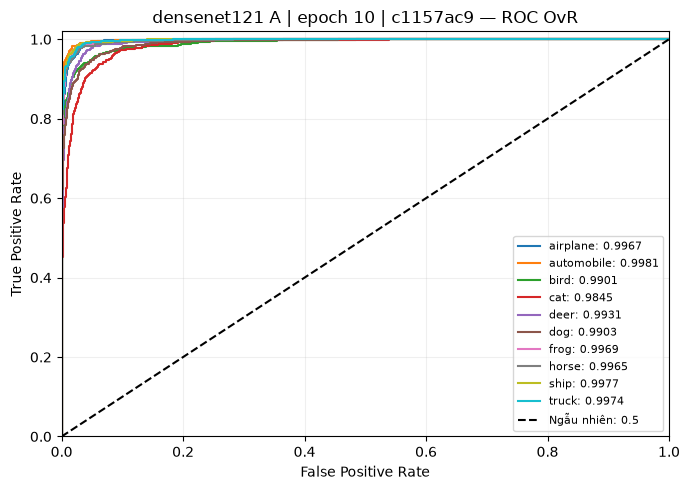

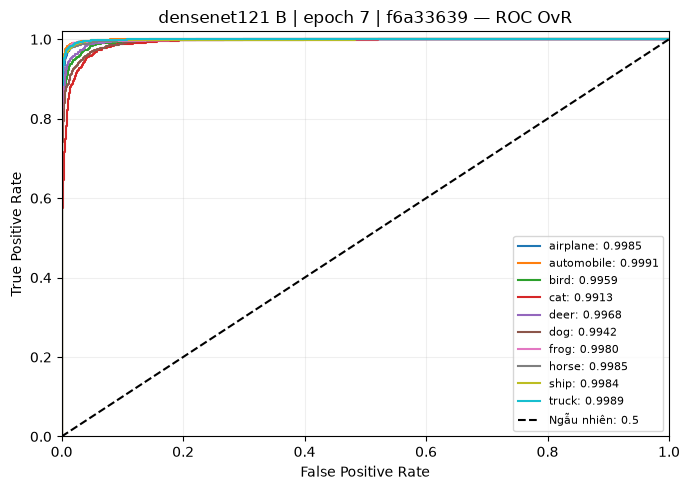

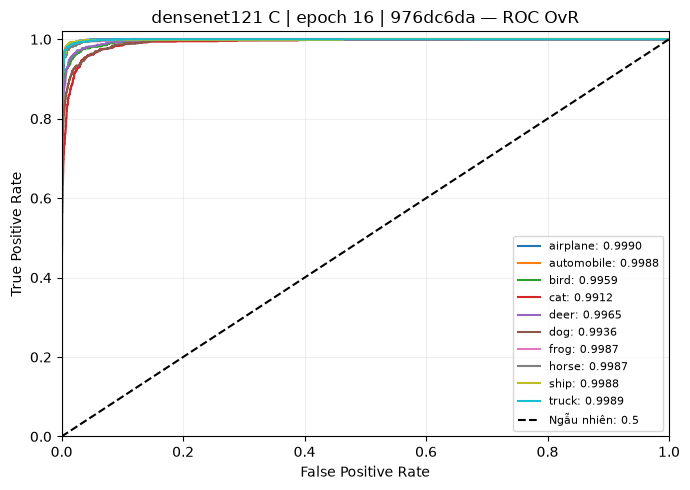

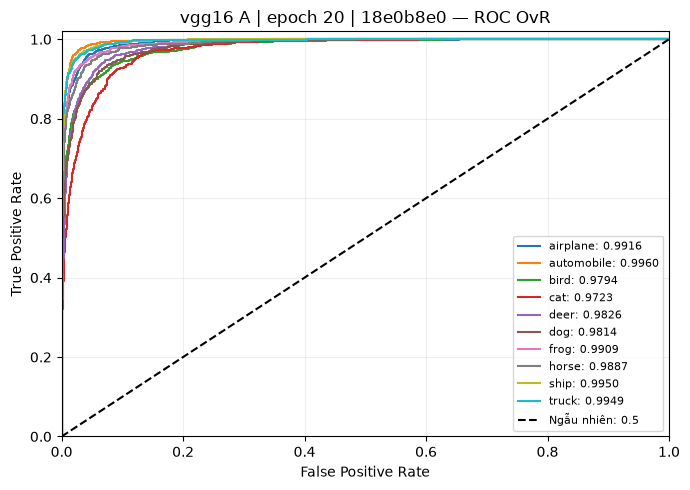

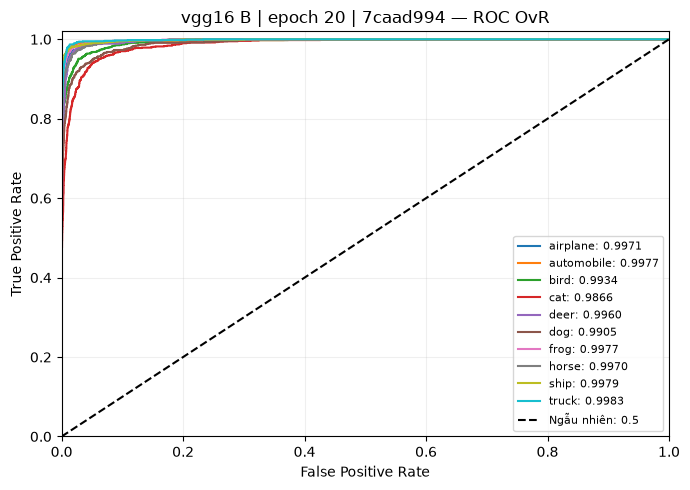

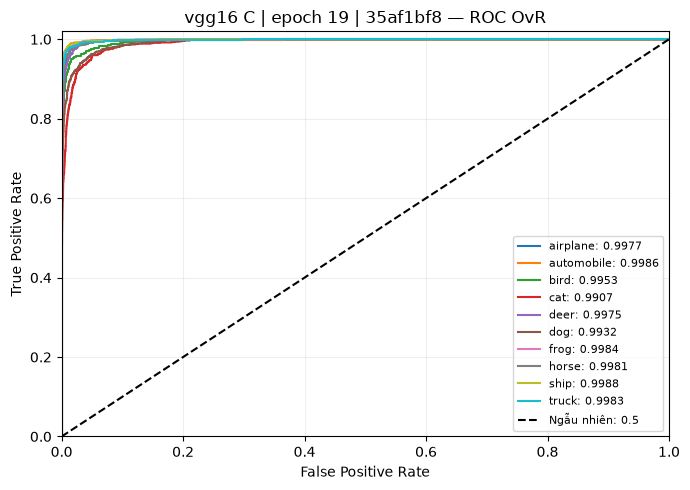

In [12]:
for label, report, table, summary, curves in test_analyses:
    class_curves = {name: curves[name] for name in report['classes'] if name in curves}
    if not class_curves:
        continue
    fig, ax = plt.subplots(figsize=(7, 5))
    for name, (fpr, tpr, auc_value) in class_curves.items():
        ax.plot(fpr, tpr, label=f'{name}: {auc_value:.4f}')
    ax.plot([0, 1], [0, 1], 'k--', label='Ngẫu nhiên: 0.5')
    ax.set(xlabel='False Positive Rate', ylabel='True Positive Rate',
           title=label + ' — ROC OvR', xlim=(0, 1), ylim=(0, 1.02))
    ax.legend(fontsize=8, loc='lower right'); ax.grid(alpha=0.2)
    plt.tight_layout(); plt.show()


### 7.3. So sánh hai model trên cùng tập test

Bảng tổng hợp đặt accuracy/Macro-F1 cạnh TPR/FPR và ROC-AUC để tránh kết luận chỉ từ một chỉ số.
So sánh trực tiếp yêu cầu cùng test split, thứ tự lớp và bộ ID/nhãn thật; checkpoint phải được chọn trước bằng validation.
Không chọn lại model, learning rate hoặc ngưỡng dự đoán theo các kết quả test này.

Đường macro ROC dùng nội suy TPR trên một lưới FPR chung; nhãn AUC hiển thị trung bình AUC từng lớp.
Đọc thêm bảng từng lớp để xác định lớp nào tạo ra chênh lệch, thay vì chỉ xét điểm trung bình.


,Accuracy,Loss,Macro-F1,Mean TPR,Mean FPR,Macro ROC-AUC,Micro ROC-AUC
Model / checkpoint,,,,,,,
densenet121 A | epoch 10 | c1157ac9,0.9001,0.2965,0.9001,0.9001,0.0111,0.9941,0.9947
densenet121 B | epoch 7 | f6a33639,0.9306,0.2502,0.9302,0.9306,0.0077,0.9969,0.9971
densenet121 C | epoch 16 | 976dc6da,0.9348,0.3283,0.9350,0.9348,0.0072,0.9970,0.9974
vgg16 A | epoch 20 | 18e0b8e0,0.8448,0.4478,0.8446,0.8448,0.0172,0.9873,0.9883
vgg16 B | epoch 20 | 7caad994,0.9191,0.4602,0.9188,0.9191,0.0090,0.9952,0.9957
vgg16 C | epoch 19 | 35af1bf8,0.9310,0.3242,0.9310,0.9310,0.0077,0.9967,0.9971


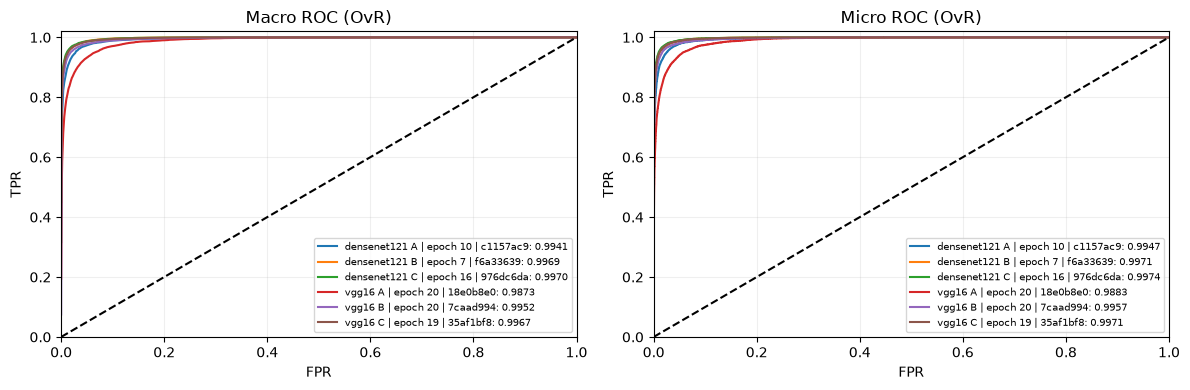

In [13]:
comparison_rows = []
if test_analyses:
    reference = test_analyses[0][1]
    reference_labels = [(r['id'], r['true']) for r in reference['predictions']]
    for label, report, table, summary, curves in test_analyses:
        labels = [(r['id'], r['true']) for r in report['predictions']]
        if (report['classes'] != reference['classes'] or labels != reference_labels or
                report['settings']['split_sha256'] != reference['settings']['split_sha256']):
            raise ValueError('Các báo cáo test không cùng split/lớp/ID/nhãn để so sánh.')
        comparison_rows.append({'Model / checkpoint': label, **summary})
    display(pd.DataFrame(comparison_rows).set_index('Model / checkpoint').round(4))

    with_scores = [entry for entry in test_analyses if entry[4]]
    if with_scores:
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        grid = np.linspace(0, 1, 1001)
        for label, report, table, summary, curves in with_scores:
            if np.isfinite(summary['Macro ROC-AUC']):
                mean_tpr = np.mean([np.interp(grid, curves[name][0], curves[name][1])
                                    for name in report['classes']], axis=0)
                axes[0].plot(grid, mean_tpr, label=f"{label}: {summary['Macro ROC-AUC']:.4f}")
            fpr, tpr, auc_value = curves['micro']
            axes[1].plot(fpr, tpr, label=f'{label}: {auc_value:.4f}')
        for ax, title in zip(axes, ('Macro ROC (OvR)', 'Micro ROC (OvR)')):
            ax.plot([0, 1], [0, 1], 'k--')
            ax.set(xlabel='FPR', ylabel='TPR', title=title, xlim=(0, 1), ylim=(0, 1.02))
            ax.legend(fontsize=7); ax.grid(alpha=0.2)
        plt.tight_layout(); plt.show()


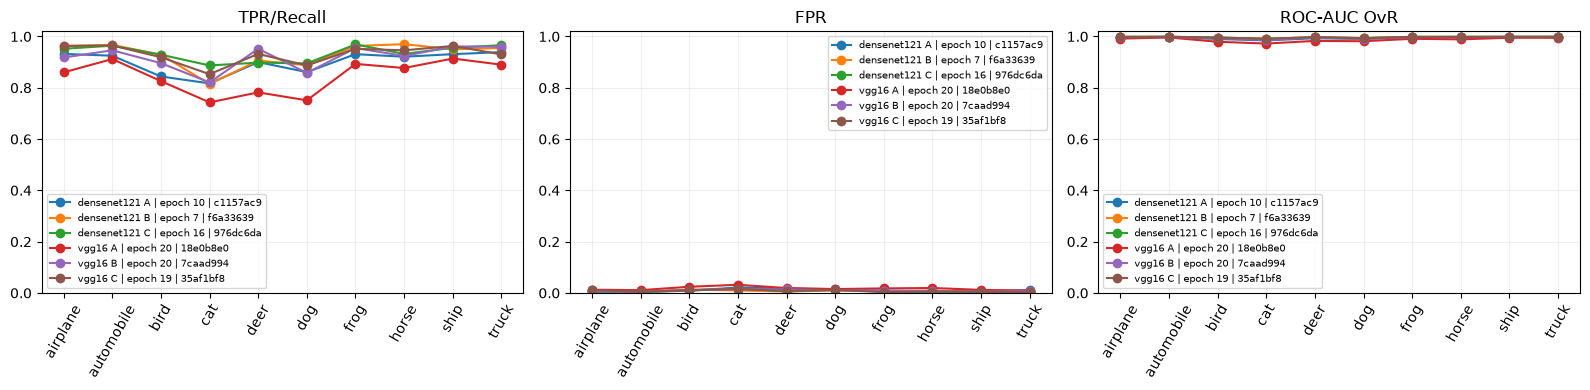

In [14]:
if test_analyses:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for label, report, table, summary, curves in test_analyses:
        for ax, metric in zip(axes, ('TPR/Recall', 'FPR', 'ROC-AUC OvR')):
            ax.plot(table['Lớp'], table[metric], marker='o', label=label)
            ax.set_title(metric); ax.tick_params(axis='x', rotation=60)
            ax.set_ylim(0, 1.02); ax.grid(alpha=0.2)
    for ax in axes:
        ax.legend(fontsize=7)
    plt.tight_layout(); plt.show()


### 7.4. Precision–Recall và Average Precision

PR curve thể hiện precision theo recall khi thay đổi ngưỡng trên xác suất của từng lớp trong thiết lập OvR.
PR bổ sung góc nhìn về chất lượng positive, đặc biệt khi số negative lớn hơn positive: mỗi lớp CIFAR-10 có tỷ lệ 1:9 trên tập test chuẩn.

**Average Precision (AP)** tổng hợp precision tại các mức tăng recall:

$$AP=\sum_n (R_n-R_{n-1})P_n$$

AP ở đây được tính bằng `average_precision_score`, không phải diện tích nội suy hình thang dưới PR curve.
Macro-AP lấy trung bình AP từng lớp; micro-AP gộp tất cả cặp ảnh–lớp.
Mức tham chiếu PR phụ thuộc tỷ lệ positive: mỗi lớp test CIFAR-10 chuẩn có prevalence 0,1; không dùng mức 0,5 của ROC.
Các chỉ số này chỉ mô tả checkpoint đã khóa, không dùng test để chọn lại ngưỡng.


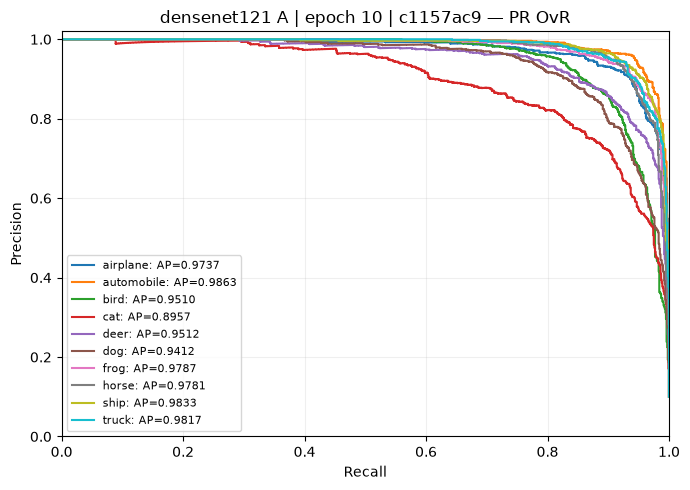

densenet121 A | epoch 10 | c1157ac9


,Lớp,Positive prevalence,AP
0,airplane,0.1,0.9737
1,automobile,0.1,0.9863
2,bird,0.1,0.9510
3,cat,0.1,0.8957
4,deer,0.1,0.9512
5,dog,0.1,0.9412
6,frog,0.1,0.9787
7,horse,0.1,0.9781
8,ship,0.1,0.9833
9,truck,0.1,0.9817


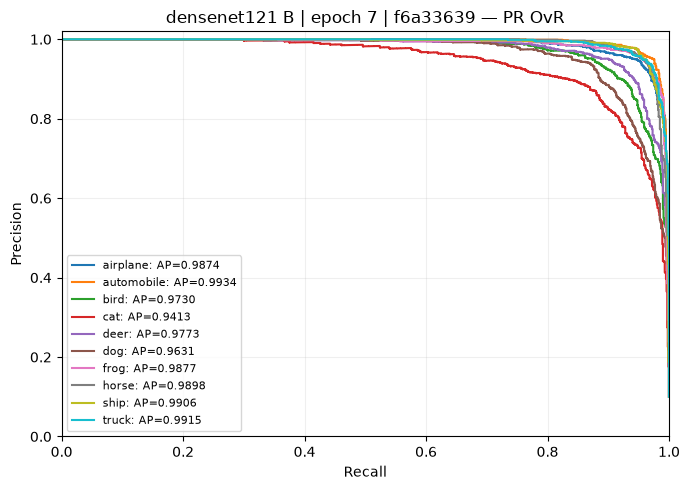

densenet121 B | epoch 7 | f6a33639


,Lớp,Positive prevalence,AP
0,airplane,0.1,0.9874
1,automobile,0.1,0.9934
2,bird,0.1,0.9730
3,cat,0.1,0.9413
4,deer,0.1,0.9773
5,dog,0.1,0.9631
6,frog,0.1,0.9877
7,horse,0.1,0.9898
8,ship,0.1,0.9906
9,truck,0.1,0.9915


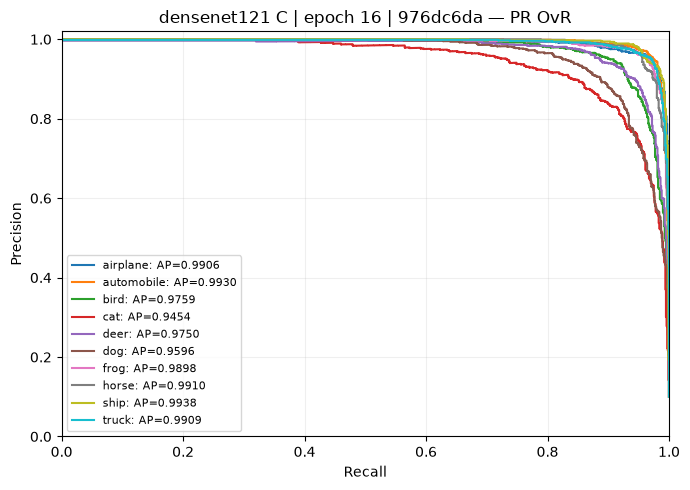

densenet121 C | epoch 16 | 976dc6da


,Lớp,Positive prevalence,AP
0,airplane,0.1,0.9906
1,automobile,0.1,0.9930
2,bird,0.1,0.9759
3,cat,0.1,0.9454
4,deer,0.1,0.9750
5,dog,0.1,0.9596
6,frog,0.1,0.9898
7,horse,0.1,0.9910
8,ship,0.1,0.9938
9,truck,0.1,0.9909


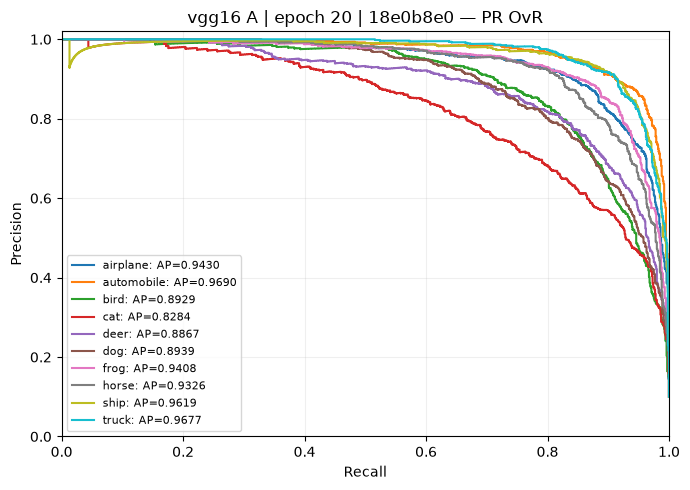

vgg16 A | epoch 20 | 18e0b8e0


,Lớp,Positive prevalence,AP
0,airplane,0.1,0.9430
1,automobile,0.1,0.9690
2,bird,0.1,0.8929
3,cat,0.1,0.8284
4,deer,0.1,0.8867
5,dog,0.1,0.8939
6,frog,0.1,0.9408
7,horse,0.1,0.9326
8,ship,0.1,0.9619
9,truck,0.1,0.9677


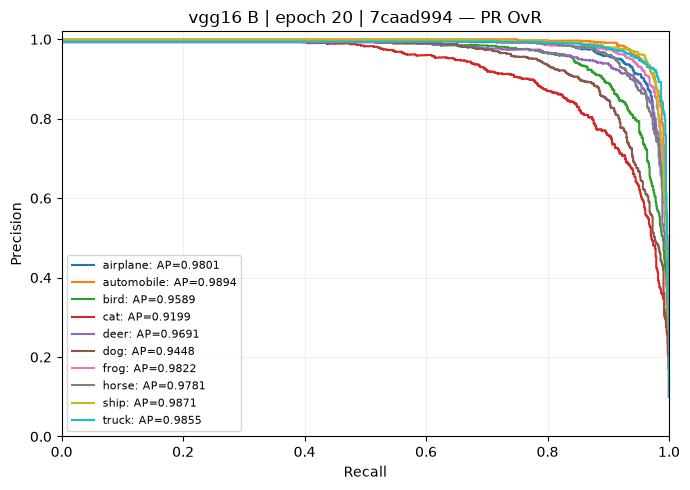

vgg16 B | epoch 20 | 7caad994


,Lớp,Positive prevalence,AP
0,airplane,0.1,0.9801
1,automobile,0.1,0.9894
2,bird,0.1,0.9589
3,cat,0.1,0.9199
4,deer,0.1,0.9691
5,dog,0.1,0.9448
6,frog,0.1,0.9822
7,horse,0.1,0.9781
8,ship,0.1,0.9871
9,truck,0.1,0.9855


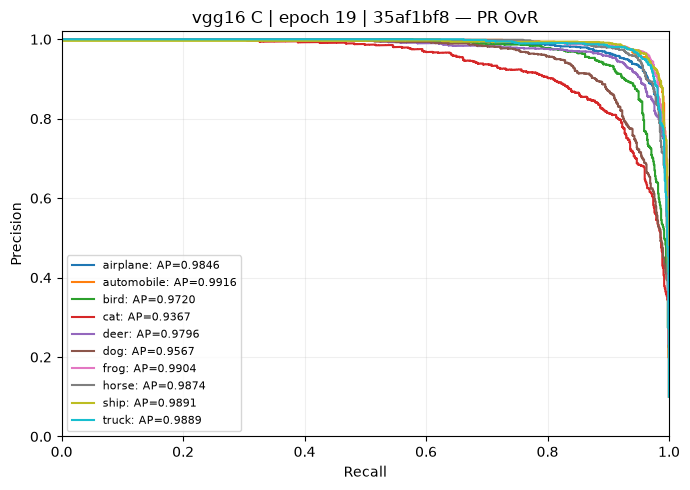

vgg16 C | epoch 19 | 35af1bf8


,Lớp,Positive prevalence,AP
0,airplane,0.1,0.9846
1,automobile,0.1,0.9916
2,bird,0.1,0.9720
3,cat,0.1,0.9367
4,deer,0.1,0.9796
5,dog,0.1,0.9567
6,frog,0.1,0.9904
7,horse,0.1,0.9874
8,ship,0.1,0.9891
9,truck,0.1,0.9889


,Macro-AP,Micro-AP
Model / checkpoint,,
densenet121 A | epoch 10 | c1157ac9,0.9621,0.9653
densenet121 B | epoch 7 | f6a33639,0.9795,0.9806
densenet121 C | epoch 16 | 976dc6da,0.9805,0.9823
vgg16 A | epoch 20 | 18e0b8e0,0.9217,0.9263
vgg16 B | epoch 20 | 7caad994,0.9695,0.9719
vgg16 C | epoch 19 | 35af1bf8,0.9777,0.9799


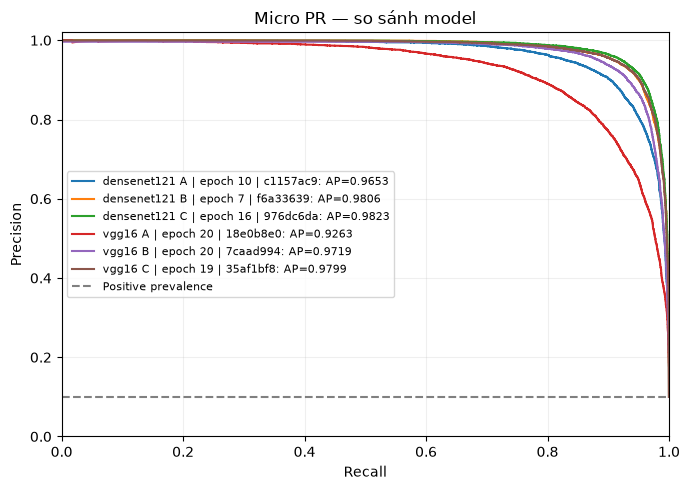

In [15]:
from sklearn.metrics import precision_recall_curve, average_precision_score

pr_summaries = []
micro_pr_curves = []
for label, report, table, summary, roc_curves in test_analyses:
    if not roc_curves:
        continue
    actual = np.array([row['true'] for row in report['predictions']], dtype=int)
    scores = np.asarray(report['probabilities'], dtype=float)
    binary = np.eye(len(report['classes']), dtype=int)[actual]
    ap_rows = []
    fig, ax = plt.subplots(figsize=(7, 5))
    for index, name in enumerate(report['classes']):
        prevalence = float(binary[:, index].mean())
        ap = np.nan
        if 0 < prevalence < 1:
            precision, recall, _ = precision_recall_curve(binary[:, index], scores[:, index])
            ap = average_precision_score(binary[:, index], scores[:, index])
            ax.step(recall, precision, where='post', label=f'{name}: AP={ap:.4f}')
        ap_rows.append({'Lớp': name, 'Positive prevalence': prevalence, 'AP': ap})
    ax.set(xlabel='Recall', ylabel='Precision', title=label + ' — PR OvR',
           xlim=(0, 1), ylim=(0, 1.02))
    ax.legend(fontsize=8, loc='lower left'); ax.grid(alpha=0.2)
    plt.tight_layout(); plt.show()
    ap_table = pd.DataFrame(ap_rows)
    print(label); display(ap_table.round(4))
    macro_ap = ap_table['AP'].mean() if ap_table['AP'].notna().all() else np.nan
    micro_ap = average_precision_score(binary.ravel(), scores.ravel())
    pr_summaries.append({'Model / checkpoint': label, 'Macro-AP': macro_ap, 'Micro-AP': micro_ap})
    precision, recall, _ = precision_recall_curve(binary.ravel(), scores.ravel())
    micro_pr_curves.append((label, recall, precision, micro_ap, binary.mean()))

if pr_summaries:
    display(pd.DataFrame(pr_summaries).set_index('Model / checkpoint').round(4))
    fig, ax = plt.subplots(figsize=(7, 5))
    for label, recall, precision, ap, baseline in micro_pr_curves:
        ax.step(recall, precision, where='post', label=f'{label}: AP={ap:.4f}')
    ax.axhline(micro_pr_curves[0][4], color='gray', linestyle='--', label='Positive prevalence')
    ax.set(xlabel='Recall', ylabel='Precision', title='Micro PR — so sánh model',
           xlim=(0, 1), ylim=(0, 1.02))
    ax.legend(fontsize=8); ax.grid(alpha=0.2); plt.tight_layout(); plt.show()
else:
    print('Chưa có xác suất test để phân tích Precision–Recall/AP.')


### 7.5. Đối chiếu hai model trong cùng cấu hình A/B/C

Ghép riêng **VGG16 A với DenseNet121 A**, tương tự cho B và C, dựa trên metadata của báo cáo. Không chọn cặp bằng điểm test cao nhất. Cặp chỉ được dùng khi cùng split, lớp, ID/nhãn và điều kiện huấn luyện tương ứng.

Mỗi cặp gồm bốn nhóm: cả hai đúng, chỉ DenseNet đúng, chỉ VGG đúng và cả hai sai. Chênh lệch accuracy DenseNet−VGG bằng `(số chỉ DenseNet đúng − số chỉ VGG đúng) / tổng số ảnh`.

Bảng theo lớp bổ sung recall của mỗi model để chỉ ra các đánh đổi. Gallery chọn tối đa bốn ID nhỏ nhất mỗi nhóm lỗi, có nhãn thật, dự đoán và confidence của cả hai model. Phần này mô tả mức phù hợp với CIFAR-10 trong điều kiện đã thử; không chứng minh ưu thế trên mọi dữ liệu hoặc nhiều seed.


In [16]:
def compare_test_errors(report_a, report_b):
    if (report_a['split'] != 'test' or report_b['split'] != 'test' or
            report_a['classes'] != report_b['classes'] or
            report_a['settings']['split_sha256'] != report_b['settings']['split_sha256']):
        raise ValueError('Hai báo cáo không cùng test split hoặc thứ tự lớp.')
    records_a = {row['id']: row for row in report_a['predictions']}
    records_b = {row['id']: row for row in report_b['predictions']}
    if (len(records_a) != report_a['count'] or len(records_b) != report_b['count'] or
            records_a.keys() != records_b.keys()):
        raise ValueError('ID test khác nhau hoặc có ID trùng.')
    rows = []
    for index in sorted(records_a):
        a, b = records_a[index], records_b[index]
        if a['true'] != b['true']:
            raise ValueError('Nhãn thật khác nhau trên cùng ID.')
        correct_a = a['predicted'] == a['true']
        correct_b = b['predicted'] == b['true']
        if correct_a and correct_b:
            group = 'Cả hai đúng'
        elif not correct_a and correct_b:
            group = 'VGG sai, DenseNet đúng'
        elif correct_a and not correct_b:
            group = 'VGG đúng, DenseNet sai'
        else:
            group = 'Cả hai sai'
        rows.append({'ID': index, 'Nhãn thật': report_a['classes'][a['true']],
                     'VGG dự đoán': report_a['classes'][a['predicted']],
                     'DenseNet dự đoán': report_b['classes'][b['predicted']],
                     'Confidence VGG': a.get('confidence', np.nan),
                     'Confidence DenseNet': b.get('confidence', np.nan), 'Kết quả': group})
    return pd.DataFrame(rows)


# Ghép theo cấu hình thực trong report, không theo tên thư mục hoặc điểm test.
paired_comparisons = []
pair_summary = []
groups = ['Cả hai đúng', 'VGG sai, DenseNet đúng', 'VGG đúng, DenseNet sai', 'Cả hai sai']
for experiment in ('A', 'B', 'C'):
    candidates = [[entry for entry in test_analyses
                   if entry[1]['settings']['model_name'] == name
                   and entry[1]['settings']['experiment'] == experiment]
                  for name in ('vgg16', 'densenet121')]
    if any(len(entries) != 1 for entries in candidates):
        print(f'Cấu hình {experiment}: cần đúng một báo cáo VGG16 và một DenseNet121; '
              f'hiện có {[len(entries) for entries in candidates]}.')
        continue
    vgg, dense = [entries[0] for entries in candidates]
    label_vgg, report_vgg = vgg[:2]
    label_dense, report_dense = dense[:2]
    if (report_vgg['settings']['model_config'] != report_dense['settings']['model_config']
            or report_vgg['settings']['train'] != report_dense['settings']['train']):
        raise ValueError(f'Cấu hình {experiment}: điều kiện huấn luyện không khớp.')
    paired_errors = compare_test_errors(report_vgg, report_dense)
    paired_comparisons.append((experiment, label_vgg, label_dense, paired_errors))
    counts = paired_errors['Kết quả'].value_counts().reindex(groups, fill_value=0)
    vgg_accuracy = report_vgg['accuracy']
    dense_accuracy = report_dense['accuracy']
    delta = (counts['VGG sai, DenseNet đúng'] - counts['VGG đúng, DenseNet sai']) / len(paired_errors)
    if not np.isclose(delta, dense_accuracy - vgg_accuracy):
        raise ValueError('Chênh lệch accuracy không khớp đối chiếu cùng ID.')
    print(f'Cấu hình {experiment} | VGG16: {label_vgg} | DenseNet121: {label_dense}')
    display(pd.DataFrame({'Số ảnh': counts, 'Tỷ lệ': counts / len(paired_errors)}))
    print(f'DenseNet − VGG: {100 * delta:+.2f} điểm phần trăm')
    by_class = pd.crosstab(paired_errors['Nhãn thật'], paired_errors['Kết quả'])
    by_class = by_class.reindex(index=report_vgg['classes'], columns=groups, fill_value=0)
    by_class['Recall VGG'] = (by_class['Cả hai đúng'] + by_class['VGG đúng, DenseNet sai']) / by_class[groups].sum(axis=1)
    by_class['Recall DenseNet'] = (by_class['Cả hai đúng'] + by_class['VGG sai, DenseNet đúng']) / by_class[groups].sum(axis=1)
    display(by_class.round(4))
    pair_summary.append({'Cấu hình': experiment, 'VGG test (%)': 100 * vgg_accuracy,
                         'DenseNet test (%)': 100 * dense_accuracy,
                         'DenseNet − VGG (điểm %)': 100 * delta,
                         **{name: int(counts[name]) for name in groups}})
if pair_summary:
    print('Tổng hợp các cặp cùng cấu hình:')
    display(pd.DataFrame(pair_summary).set_index('Cấu hình').round(2))
    print('Đây là kết quả trên split/seed hiện có; đọc cùng validation, chi phí và giới hạn một seed. '
          'Không dùng test để chọn lại siêu tham số.')


Cấu hình A | VGG16: vgg16 A | epoch 20 | 18e0b8e0 | DenseNet121: densenet121 A | epoch 10 | c1157ac9


,Số ảnh,Tỷ lệ
Kết quả,,
Cả hai đúng,8028,0.8028
"VGG sai, DenseNet đúng",973,0.0973
"VGG đúng, DenseNet sai",420,0.0420
Cả hai sai,579,0.0579


DenseNet − VGG: +5.53 điểm phần trăm


Kết quả,Cả hai đúng,"VGG sai, DenseNet đúng","VGG đúng, DenseNet sai",Cả hai sai,Recall VGG,Recall DenseNet
Nhãn thật,,,,,,
airplane,832,100,28,40,0.860,0.932
automobile,869,56,43,32,0.912,0.925
bird,759,85,67,89,0.826,0.844
cat,661,156,82,101,0.743,0.817
deer,743,157,39,61,0.782,0.900
dog,712,149,39,100,0.751,0.861
frog,862,69,31,38,0.893,0.931
horse,844,77,33,46,0.877,0.921
ship,879,52,35,34,0.914,0.931


Cấu hình B | VGG16: vgg16 B | epoch 20 | 7caad994 | DenseNet121: densenet121 B | epoch 7 | f6a33639


...

DenseNet − VGG: +0.38 điểm phần trăm


Kết quả,Cả hai đúng,"VGG sai, DenseNet đúng","VGG đúng, DenseNet sai",Cả hai sai,Recall VGG,Recall DenseNet
Nhãn thật,,,,,,
airplane,930,22,33,15,0.963,0.952
automobile,943,21,22,14,0.965,0.964
bird,883,46,36,35,0.919,0.929
cat,793,94,60,53,0.853,0.887
deer,857,41,75,27,0.932,0.898
dog,835,60,52,53,0.887,0.895
frog,939,30,13,18,0.952,0.969
horse,903,29,43,25,0.946,0.932
ship,937,19,26,18,0.963,0.956


Tổng hợp các cặp cùng cấu hình:


,VGG test (%),DenseNet test (%),DenseNet − VGG (điểm %),Cả hai đúng,"VGG sai, DenseNet đúng","VGG đúng, DenseNet sai",Cả hai sai
Cấu hình,,,,,,,
A,84.48,90.01,5.53,8028,973,420,579
B,91.91,93.06,1.15,8802,504,389,305
C,93.10,93.48,0.38,8943,405,367,285


Đây là kết quả trên split/seed hiện có; đọc cùng validation, chi phí và giới hạn một seed. Không dùng test để chọn lại siêu tham số.


In [17]:
test_images = None
test_path = project / 'data' / 'cifar-10-batches-py' / 'test_batch'
if paired_comparisons and test_path.exists():
    from torchvision.datasets import CIFAR10
    test_images = CIFAR10(root=str(project / 'data'), train=False, download=False)

for experiment, label_vgg, label_dense, paired_errors in paired_comparisons:
    # Bốn ID nhỏ nhất trong mỗi nhóm lỗi: chọn có quy tắc, không chọn ảnh đẹp.
    wrong_groups = ['VGG sai, DenseNet đúng', 'VGG đúng, DenseNet sai', 'Cả hai sai']
    selections = [paired_errors[paired_errors['Kết quả'] == group].head(4) for group in wrong_groups]
    examples = pd.concat(selections, ignore_index=True)
    print(f'Cấu hình {experiment}: ví dụ lỗi trên cùng ảnh test')
    display(examples)
    if not len(examples):
        continue
    if test_images is None:
        print('Chưa có dataset test local; vẫn xem được bảng đối chiếu.')
        continue
    if examples['ID'].min() < 0 or examples['ID'].max() >= len(test_images):
        raise ValueError('ID báo cáo không thuộc dataset test local.')
    rows = (len(examples) + 3) // 4
    fig, axes = plt.subplots(rows, 4, figsize=(14, rows * 3.6), squeeze=False)
    for ax, (_, example) in zip(axes.flat, examples.iterrows()):
        index = int(example['ID'])
        if test_images.classes[test_images.targets[index]] != example['Nhãn thật']:
            raise ValueError('Dataset local không khớp nhãn báo cáo.')
        ax.imshow(test_images.data[index])
        ax.set_title(f"ID {index} | {example['Kết quả']}\nThật: {example['Nhãn thật']}\n"
                     f"VGG: {example['VGG dự đoán']} ({example['Confidence VGG']:.2f})\n"
                     f"DenseNet: {example['DenseNet dự đoán']} ({example['Confidence DenseNet']:.2f})", fontsize=8)
        ax.axis('off')
    for ax in list(axes.flat)[len(examples):]:
        ax.axis('off')
    fig.suptitle(f'Cấu hình {experiment} | VGG16 so với DenseNet121')
    plt.tight_layout(); plt.show()
if test_images is not None:
    del test_images


Cấu hình A: ví dụ lỗi trên cùng ảnh test


,ID,Nhãn thật,VGG dự đoán,DenseNet dự đoán,Confidence VGG,Confidence DenseNet,Kết quả
0,40,deer,bird,deer,0.790981,0.393791,"VGG sai, DenseNet đúng"
1,65,bird,frog,bird,0.860489,0.953103,"VGG sai, DenseNet đúng"
2,68,cat,deer,cat,0.397942,0.382611,"VGG sai, DenseNet đúng"
3,74,airplane,truck,airplane,0.663272,0.527420,"VGG sai, DenseNet đúng"
4,25,bird,bird,horse,0.668720,0.877106,"VGG đúng, DenseNet sai"
5,26,deer,deer,dog,0.565143,0.635113,"VGG đúng, DenseNet sai"
6,60,horse,horse,deer,0.784616,0.510246,"VGG đúng, DenseNet sai"
7,62,frog,frog,bird,0.961857,0.320624,"VGG đúng, DenseNet sai"
8,35,bird,dog,cat,0.453083,0.623475,Cả hai sai
9,37,automobile,truck,truck,0.588110,0.675548,Cả hai sai


Cấu hình B: ví dụ lỗi trên cùng ảnh test


,ID,Nhãn thật,VGG dự đoán,DenseNet dự đoán,Confidence VGG,Confidence DenseNet,Kết quả
0,2,ship,automobile,ship,0.892496,0.998348,"VGG sai, DenseNet đúng"
1,12,dog,cat,dog,0.742582,0.979068,"VGG sai, DenseNet đúng"
2,57,horse,cat,horse,0.919782,0.877614,"VGG sai, DenseNet đúng"
3,58,deer,dog,deer,0.519774,0.507404,"VGG sai, DenseNet đúng"
4,68,cat,cat,frog,0.785453,0.174151,"VGG đúng, DenseNet sai"
5,78,cat,cat,dog,0.957191,0.695922,"VGG đúng, DenseNet sai"
6,85,dog,dog,horse,0.999189,0.637965,"VGG đúng, DenseNet sai"
7,86,bird,bird,horse,0.591789,0.851637,"VGG đúng, DenseNet sai"
8,37,automobile,truck,truck,0.930486,0.720644,Cả hai sai
9,59,frog,cat,cat,0.635291,0.525522,Cả hai sai


Cấu hình C: ví dụ lỗi trên cùng ảnh test


,ID,Nhãn thật,VGG dự đoán,DenseNet dự đoán,Confidence VGG,Confidence DenseNet,Kết quả
0,35,bird,cat,bird,0.801522,0.954097,"VGG sai, DenseNet đúng"
1,78,cat,dog,cat,0.813286,0.857265,"VGG sai, DenseNet đúng"
2,158,dog,cat,dog,0.726429,1.000000,"VGG sai, DenseNet đúng"
3,188,deer,dog,deer,0.984673,0.999975,"VGG sai, DenseNet đúng"
4,37,automobile,automobile,truck,0.993152,0.997105,"VGG đúng, DenseNet sai"
5,68,cat,cat,bird,0.984601,0.456687,"VGG đúng, DenseNet sai"
6,81,automobile,automobile,truck,0.999853,0.960927,"VGG đúng, DenseNet sai"
7,117,deer,deer,cat,0.999871,0.583252,"VGG đúng, DenseNet sai"
8,57,horse,cat,cat,0.509415,0.996688,Cả hai sai
9,58,deer,cat,cat,0.902739,0.679496,Cả hai sai


### 7.6. Nhận xét từ kết quả thực nghiệm

- DenseNet121 có test accuracy cao hơn VGG16 trong cả A/B/C: **5,53 / 1,15 / 0,38 điểm phần trăm**. Lợi thế thu hẹp khi fine-tune với LR nhỏ; chưa thể khẳng định chênh lệch nhỏ ở C ổn định qua nhiều seed.
- Cấu hình A đánh giá chất lượng đặc trưng pretrained khi backbone cố định. B cải thiện rõ ở cả hai kiến trúc khi mở nhóm cuối; C cho kết quả tốt hơn B khi giảm LR từ 0,001 xuống 0,0001.
- Với C, VGG16 đạt **93,10%** và DenseNet121 đạt **93,48%** test. DenseNet sửa đúng **405** ảnh VGG sai nhưng làm sai **367** ảnh VGG đúng: không có cải thiện đồng đều trên mọi ảnh.
- DenseNet C train eval **99,75%**, validation eval **93,88%**: gap còn khoảng **5,86 điểm phần trăm**. Đọc cùng loss và recall từng lớp; chưa thử scheduler/weight decay nên không kết luận chúng có/không giải quyết được gap.
- ROC-AUC và AP mô tả khả năng xếp hạng từ xác suất; accuracy/F1 mô tả quyết định argmax. Không dùng một đường cong tách cụm đẹp hoặc AUC cao để thay thế phân tích lỗi.

Các số liệu là kết quả checkpoint trên split hiện có. Gallery test và bản đồ phân bố 60.000 ảnh nằm trong [HTML](visualization/eda.html). Bản đồ dùng pixel RGB 8×8, PCA fit trên train rồi transform tất cả ảnh; không dùng model hoặc train thêm.


## 8. Kết luận, giới hạn và đối chiếu yêu cầu

Đã thực hiện **hai kiến trúc × ba cấu hình = sáu lượt**, mỗi lượt đủ **20 epoch**, cùng CIFAR-10 và chính sách head Linear 10 lớp. Sáu best checkpoint cùng các last checkpoint đã được lưu, kiểm tra kiến trúc và đối chiếu với báo cáo.

Trong phạm vi thí nghiệm này, fine-tuning hiệu quả hơn chỉ train head. Cấu hình C có validation accuracy tốt nhất trong các cấu hình đã thử của mỗi kiến trúc; kết quả test được dùng để mô tả sau đánh giá, không để chọn lại cấu hình. DenseNet có lợi thế accuracy nhưng cần đọc cùng số tham số, từng lớp và các ảnh sai thêm.

### Đối chiếu checklist

| Nội dung | Bằng chứng |
|---|---|
| Dataset và EDA | CIFAR-10, split 45k/5k/10k seed42, thống kê/ảnh cực trị và HTML |
| Hai pretrained CNN | VGG16 và DenseNet121, ImageNet-1K V1 |
| Thay classifier / transfer learning | GAP → flatten → Linear 10; A chỉ train head |
| Fine-tuning | B/C mở nhóm cuối, giữ chính sách BatchNorm cố định |
| Điều chỉnh hyperparameters | B/C so LR 0,001/0,0001; batch cố định 64, chưa khảo sát batch size |
| Train và lưu model | Sáu history 20 epoch, config/train log, best/last |
| TensorBoard | Theo dõi scalars; events local hiện có ở lan_2/lan_3, history đủ sáu run |
| Evaluation | Sáu báo cáo train/val/test cùng best checkpoint, confusion và per-class |
| Comparison | Bảng sáu run, ROC/PR, cặp A/B/C cùng ID và gallery HTML |

### Giới hạn

- Một seed và một split; chưa có khoảng biến thiên hoặc bằng chứng ưu thế thống kê.
- Các run thực hiện trên máy và phiên bản thư viện khác nhau. Cùng thiết lập thí nghiệm không bảo đảm phép so sánh thời gian công bằng; kết quả inference giữa máy có thể lệch một vài ảnh.
- Test đã được quan sát cho cả sáu cấu hình. Đây là báo cáo các thí nghiệm đã thực hiện, không phải ước lượng độc lập sau một lần chọn model duy nhất; không tiếp tục tune bằng test.
- Chưa thử LR scheduler, weight decay khác 0, nhiều batch size hoặc nhiều mức mở backbone. Đây là giới hạn phạm vi, không trình bày như thí nghiệm đã làm.
- Bản đồ PCA dùng pixel ảnh thu nhỏ, không phải đặc trưng đã học. Hai chiều chỉ giữ một phần phương sai; không suy độ chính xác model hoặc mức tách lớp trong không gian gốc chỉ từ hình này.

### Tài liệu tham khảo

- [Yêu cầu Practice 2](Practice_2_Pretrained_CNN_Requirements.md).
- [Thiết kế thí nghiệm](Experiment_Plan.md), [giải thích mô hình/tham số](Model_QA.md).
- [CIFAR-10](https://www.cs.toronto.edu/~kriz/cifar.html).
- [scikit-learn — Multiclass ROC](https://scikit-learn.org/stable/auto_examples/model_selection/plot_roc.html).
- [scikit-learn — Precision–Recall](https://scikit-learn.org/stable/auto_examples/model_selection/plot_precision_recall.html).
